<a href="https://colab.research.google.com/github/hend-22/-IT326-Project/blob/main/Phase4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Daily Stress Level Prediction Using Wearable and Lifestyle Data**

# **[1] Problem**

Stress is a common problem that many people experience in their daily lives, yet they may not be aware of how everyday lifestyle factors such as sleep, physical activity, diet, and caffeine intake are associated with their stress levels. Understanding the relationship between these factors and daily stress levels can help identify which aspects of an individual's lifestyle may be linked to higher or lower levels of stress.




# **[2] Data Mining Task**

This problem is formulated as both a classification and clustering task.

 In the classification task, the objective is to predict the Daily Stress Level (Low, Medium, or High) using wearable and lifestyle attributes such as sleep, physical activity, diet, and health measurements.

 In the clustering task, the objective is to group individuals with similar lifestyle and health characteristics in order to discover hidden patterns and relationships within the dataset. These tasks help in understanding the factors associated with stress levels and identifying meaningful stress related profiles.

# **[3] Data**

The dataset used in this study contains 10,000 instances and 16 attributes collected from wearable device measurements and lifestyle related information.

The attributes represent different aspects of an individual's daily routine and health condition, including demographic information such as age and gender, lifestyle factors such as physical activity level, diet type, caffeine intake, water intake, and screen time, as well as health and sleep related measurements including BMI, daily steps, calories burned, resting heart rate, sleep duration, deep sleep hours, and sleep quality score.

In Phase 1, the raw dataset was selected and explored. It was obtained from Kaggle and contains 10000 records and 16 attributes covering demographics, lifestyle habits, wearable measurements, sleep quality, and daily stress levels.
The class attribute is Daily_Stress_Level, which has three classes:  Low (5,789 instances), Medium (3,786 instances), and High (425 instances).

 In Phase 2, the raw dataset was explored using descriptive statistics, outlier detection, and visualizations. Missing values were identified in four attributes: BMI, Caffeine_Intake_mg, Resting_Heart_Rate, and Daily_Sleep_Hours.

## Dataset Source

Source: Kaggle  
URL: https://www.kaggle.com/datasets/itzzomkar/wearable-tech-sleep-quality-and-stress/data

## Dataset Description


In [ ]:
import pandas as pd

url= "https://raw.githubusercontent.com/hend-22/-IT326-Project/main/Dataset/Raw_dataset.csv"
df = pd.read_csv(url)
df.shape

(10000, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   User_ID                  10000 non-null  object 
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  object 
 3   Physical_Activity_Level  10000 non-null  object 
 4   Diet_Type                10000 non-null  object 
 5   BMI                      9790 non-null   float64
 6   Caffeine_Intake_mg       9794 non-null   float64
 7   Water_Intake_liters      10000 non-null  float64
 8   Screen_Time_Hours        10000 non-null  float64
 9   Daily_Steps              10000 non-null  int64  
 10  Calories_Burned          10000 non-null  int64  
 11  Resting_Heart_Rate       9781 non-null   float64
 12  Daily_Sleep_Hours        9810 non-null   float64
 13  Deep_Sleep_Hours         10000 non-null  float64
 14  Sleep_Quality_Score    

In [ ]:
df['Daily_Stress_Level'].value_counts()

,count
Daily_Stress_Level,
Low,5789
Medium,3786
High,425


In [ ]:
df.head()

,User_ID,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,U00001,56,Female,Low,Healthy,25.1,99.0,1.6,3.9,4731,1697,74.0,6.6,1.5,4.0,Low
1,U00002,69,Male,Low,Average,25.8,104.0,2.2,3.9,4440,1377,70.0,8.0,2.4,5.3,Low
2,U00003,46,Male,Low,Average,24.0,188.0,1.4,5.5,5023,1289,72.0,8.2,1.9,5.0,Medium
3,U00004,32,Female,Medium,Healthy,25.5,124.0,3.1,9.8,6082,1683,69.0,7.4,2.5,3.9,Low
4,U00005,60,Male,Medium,Unhealthy,NaN,0.0,2.4,5.3,7285,1621,73.0,7.9,2.2,5.2,Low


## Dataset Information

- Number of instances: 10,000
- Number of attributes: 16
- Data types: 8 float, 3 integer, and 5 object attributes
- Class attribute: Daily_Stress_Level
- Class values:
  - Low: 5,789
  - Medium: 3,786
  - High: 425

##Data Analysis

##Five-Number Summary

####The five-number summary is used to describe the distribution of the numerical attributes using the minimum, first quartile (Q1), median, third quartile (Q3), and maximum values.

In [ ]:
df.describe().loc[['min', '25%', '50%', '75%', 'max']]


,Age,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score
min,18.0,17.5,0.0,0.5,2.0,1000.00,491.0,50.0,3.5,0.7,1.0
25%,31.0,22.3,100.0,2.0,5.3,4919.50,1354.0,61.0,6.3,1.4,3.5
50%,43.0,25.1,201.0,2.5,7.1,7396.50,1561.0,67.0,7.0,1.7,4.2
75%,56.0,27.8,303.0,3.0,8.7,10119.25,1786.0,73.0,7.6,2.1,4.8
max,69.0,38.0,730.0,5.0,14.0,23451.00,2901.0,95.0,10.9,3.4,7.5


The results show clear differences in the ranges of the numerical attributes. For example, Caffeine_Intake_mg ranges from 0 to 730, Daily_Steps from 1,000 to 23,451, while Daily_Sleep_Hours ranges from 3.5 to 10.9. These differences were considered during preprocessing.

##Statistical Summary

The statistical summary provides descriptive statistics for the numerical attributes, including count, mean, standard deviation, minimum, quartiles, and maximum values.

In [ ]:
df.describe()

,Age,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score
count,10000.000000,9790.000000,9794.000000,10000.000000,10000.000000,10000.000000,10000.000000,9781.000000,9810.000000,10000.000000,10000.000000
mean,43.539400,25.087406,207.365224,2.502550,7.060990,7963.857000,1573.986300,66.944177,6.957951,1.750610,4.170080
std,14.911636,3.905276,137.681368,0.802058,2.443689,4021.490815,320.153851,8.450527,0.907726,0.467773,0.914011
min,18.000000,17.500000,0.000000,0.500000,2.000000,1000.000000,491.000000,50.000000,3.500000,0.700000,1.000000
25%,31.000000,22.300000,100.000000,2.000000,5.300000,4919.500000,1354.000000,61.000000,6.300000,1.400000,3.500000
50%,43.000000,25.100000,201.000000,2.500000,7.100000,7396.500000,1561.000000,67.000000,7.000000,1.700000,4.200000
75%,56.000000,27.800000,303.000000,3.000000,8.700000,10119.250000,1786.000000,73.000000,7.600000,2.100000,4.800000
max,69.000000,38.000000,730.000000,5.000000,14.000000,23451.000000,2901.000000,95.000000,10.900000,3.400000,7.500000


The statistical summary shows differences among the numerical attributes. Daily_Steps has the largest standard deviation in the table. Also, the count is below 10,000 for BMI, Caffeine_Intake_mg, Resting_Heart_Rate, and Daily_Sleep_Hours, which confirms that these attributes contain missing values.

##Outliers Detection

####Outliers are detected using the Interquartile Range (IQR) method. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are considered outliers.

In [ ]:
# Select numerical attributes
numeric_columns = df.select_dtypes(include='number').columns

# Detect outliers using the IQR method
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    print(column, ":", len(outliers), "outliers")

Age : 0 outliers
BMI : 25 outliers
Caffeine_Intake_mg : 25 outliers
Water_Intake_liters : 47 outliers
Screen_Time_Hours : 38 outliers
Daily_Steps : 182 outliers
Calories_Burned : 59 outliers
Resting_Heart_Rate : 7 outliers
Daily_Sleep_Hours : 43 outliers
Deep_Sleep_Hours : 9 outliers
Sleep_Quality_Score : 43 outliers


The outlier detection results show that most numerical attributes contain outliers. Daily_Steps has the highest number with 182 outliers, while Age has no outliers. Calories_Burned has 59 outliers, followed by Water_Intake_liters with 47. The remaining numerical attributes contain fewer outliers.

##Boxplots

####Boxplots are used to visualize the distribution of the numerical attributes and identify potential outliers.

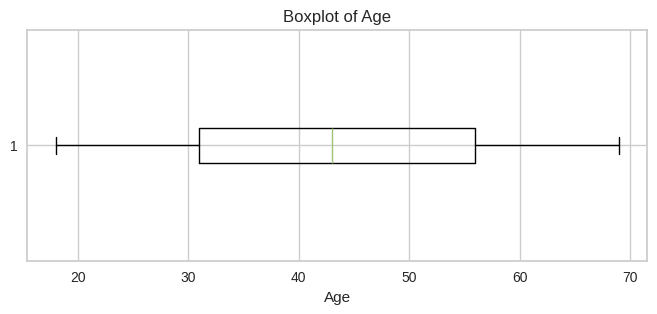

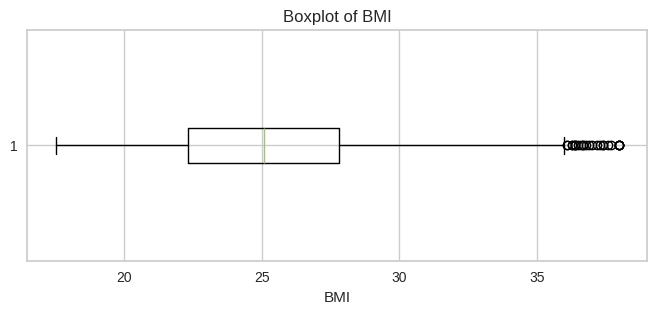

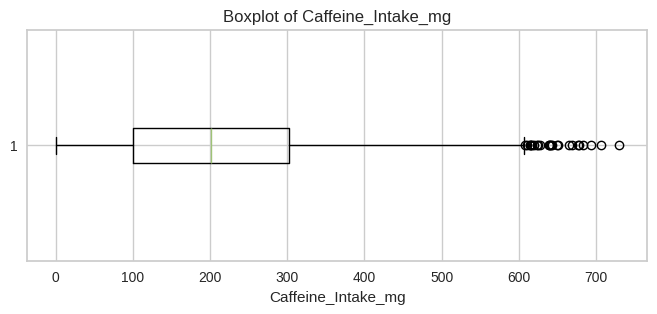

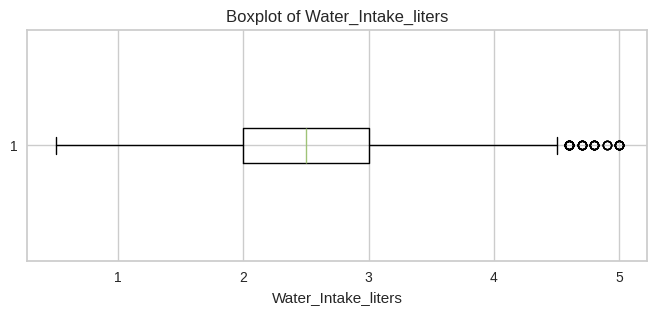

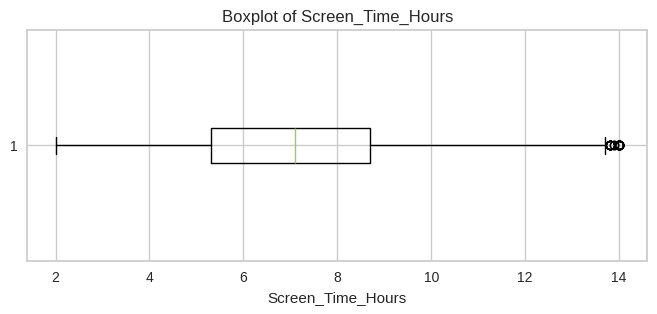

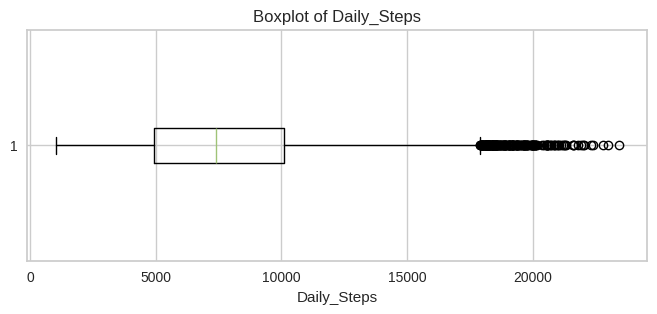

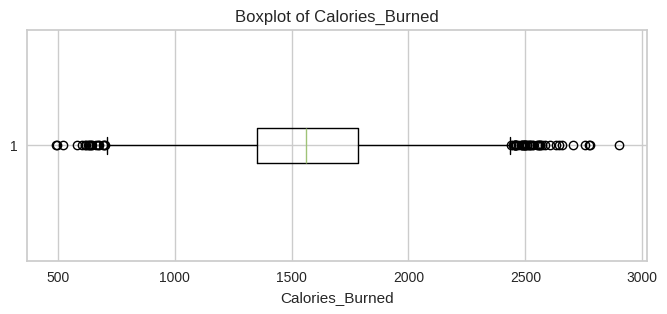

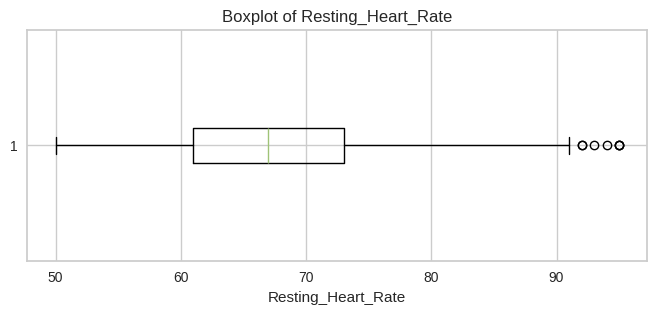

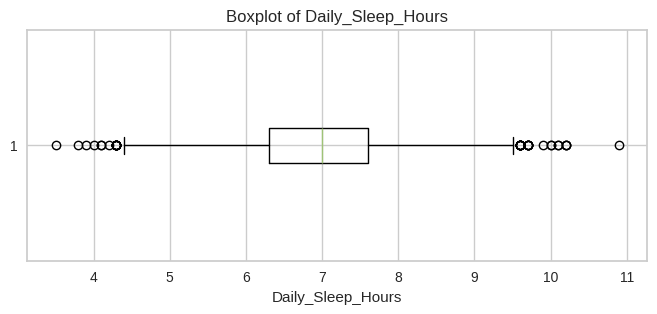

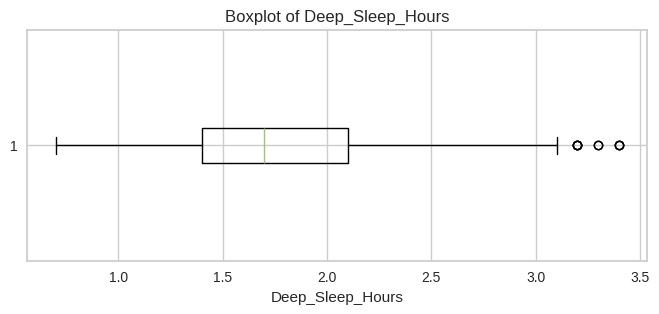

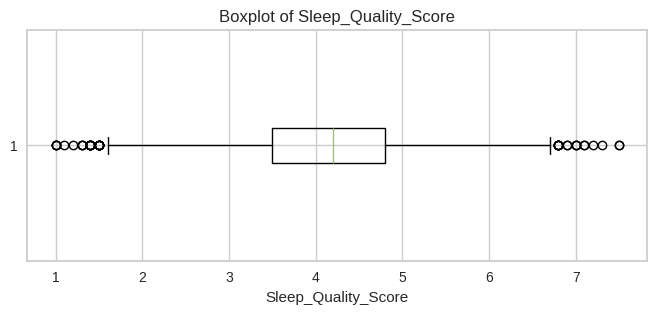

In [ ]:
import matplotlib.pyplot as plt

numeric_columns = df.select_dtypes(include='number').columns

for column in numeric_columns:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)
    plt.show()

##Boxplot Analysis
The boxplots confirm that several numerical attributes contain outliers. Daily_Steps has the highest number of outliers with 182 values, while Age has no detected outliers. Other numerical attributes also contain some outliers.


##Histograms and Variable Distributions


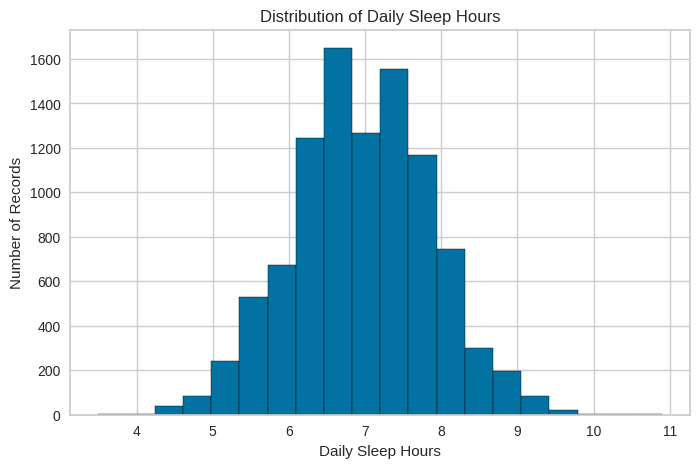

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
plt.hist(df['Daily_Sleep_Hours'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of Daily Sleep Hours')
plt.xlabel('Daily Sleep Hours')
plt.ylabel('Number of Records')
plt.show()

**Interpretation:**  Most daily sleep-hour values are
concentrated between approximately 6 and 8 hours. Fewer records appear at very low or high sleep durations. The distribution should be considered when checking unusual values during preprocessing.

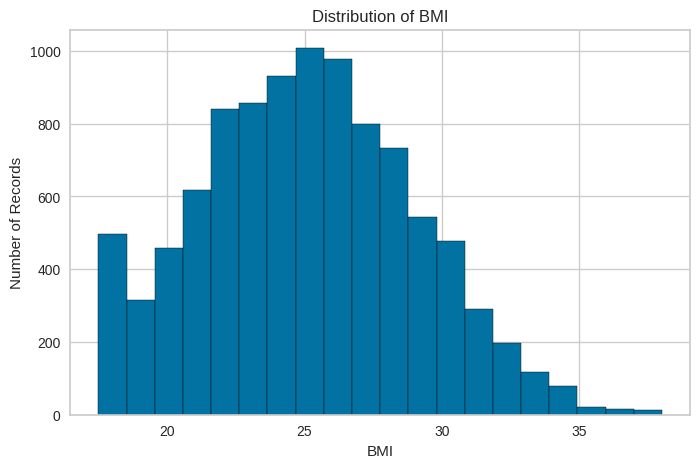

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['BMI'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of BMI')
plt.xlabel('BMI')
plt.ylabel('Number of Records')
plt.show()

**Interpretation:** Most BMI values are concentrated between approximately 22 and 28, with a peak near 25. Higher BMI values are less frequent and form a tail on the right. These values should be checked during preprocessing before deciding whether they need any treatment.


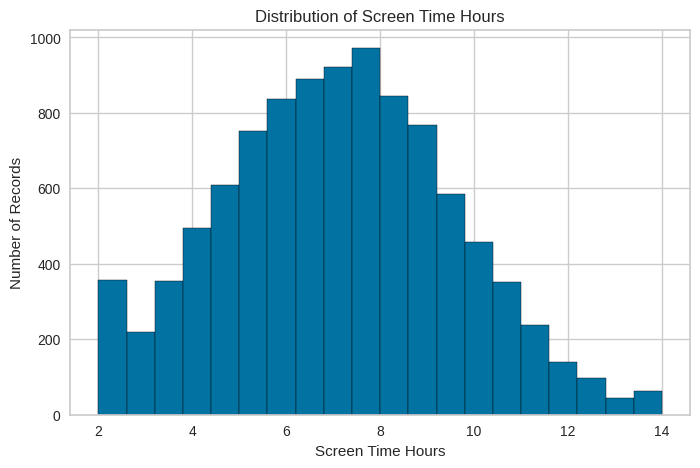

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['Screen_Time_Hours'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of Screen Time Hours')
plt.xlabel('Screen Time Hours')
plt.ylabel('Number of Records')
plt.show()

**Interpretation:** Most screen-time values are concentrated between approximately 5 and 10 hours, with the highest frequency around 7–8 hours. Very low and very high screen-time values are less common. Values at the ends of the distribution should be reviewed during preprocessing before deciding whether any treatment is needed.

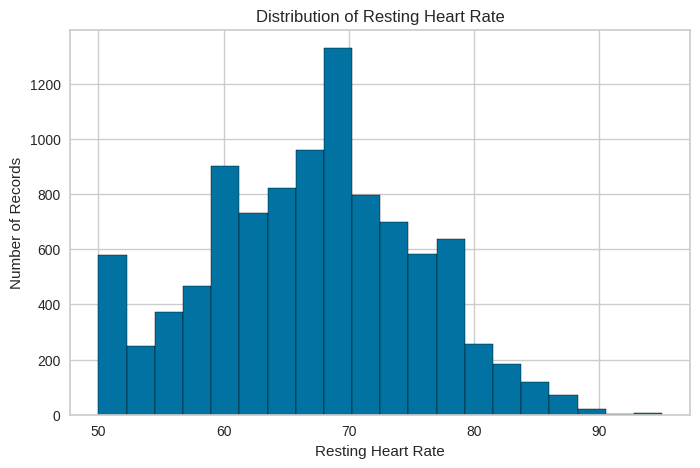

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['Resting_Heart_Rate'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of Resting Heart Rate')
plt.xlabel('Resting Heart Rate')
plt.ylabel('Number of Records')
plt.show()

**Interpretation:** Most resting heart rate values are concentrated between approximately 58 and 78, with the highest frequency around 68–70. Values above 85 are less common. These high values should be reviewed during preprocessing before deciding whether they require treatment.

##Scatter Plot

A scatter plot shows the relationship between two variables. Each point represents one person, helping us see whether changes in one variable are linked to changes in another.

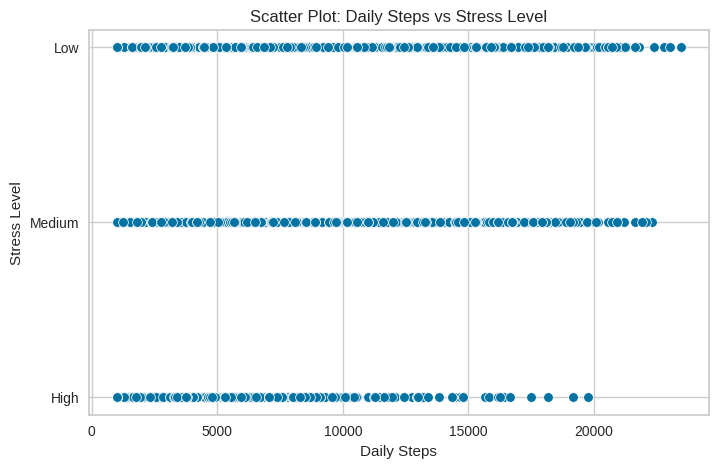

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Daily_Steps'], y=df['Daily_Stress_Level'])
plt.title('Scatter Plot: Daily Steps vs Stress Level')
plt.xlabel('Daily Steps')
plt.ylabel('Stress Level')
plt.show()

**Interpretation:** The scatter plot shows that daily step values are spread across all stress levels without forming a strong pattern. High stress appears less frequent among individuals with very high step counts.
The step values are much larger than other attributes, so scaling is needed.

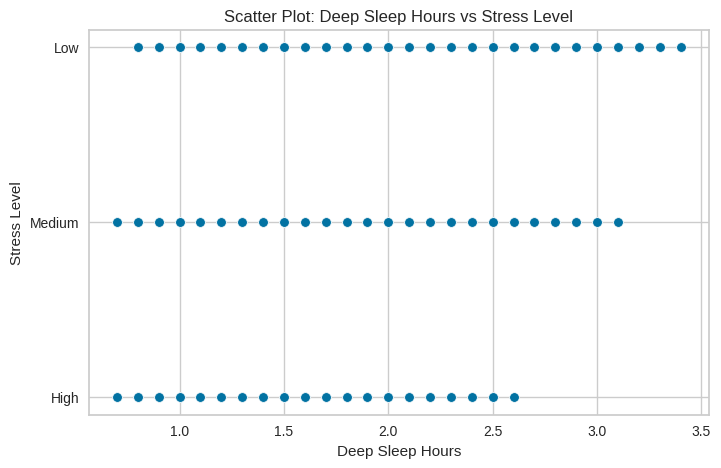

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Deep_Sleep_Hours'], y=df['Daily_Stress_Level'])
plt.title('Scatter Plot: Deep Sleep Hours vs Stress Level')
plt.xlabel('Deep Sleep Hours')
plt.ylabel('Stress Level')
plt.show()

**Interpretation:**   The scatter plot shows that deep sleep hours vary across all stress levels, with high stress appearing less frequent at higher deep sleep values.
Its range is small compared to other attributes, so the attributes need to be put on a comparable scale  before they are used together.

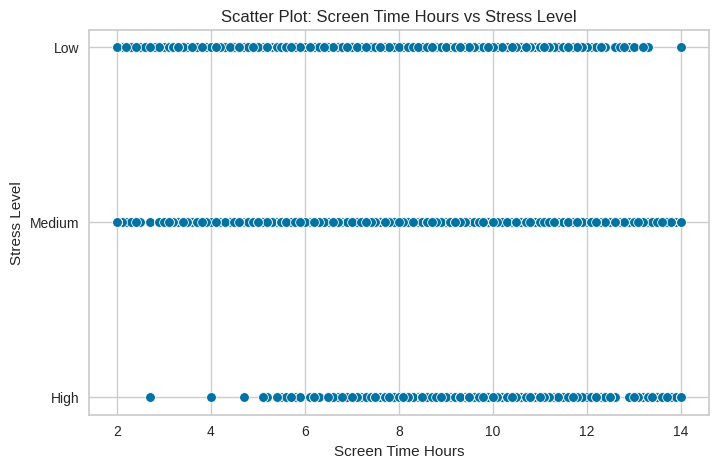

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Screen_Time_Hours'], y=df['Daily_Stress_Level'])
plt.title('Scatter Plot: Screen Time Hours vs Stress Level')
plt.xlabel('Screen Time Hours')
plt.ylabel('Stress Level')
plt.show()

**Interpretation:** The scatter plot shows that screen time hours are distributed across all stress levels, with high stress less common at very low screen time.
This attribute looks useful, so it should be kept, but it is measured in hours and needs scaling like other numerical attributes.

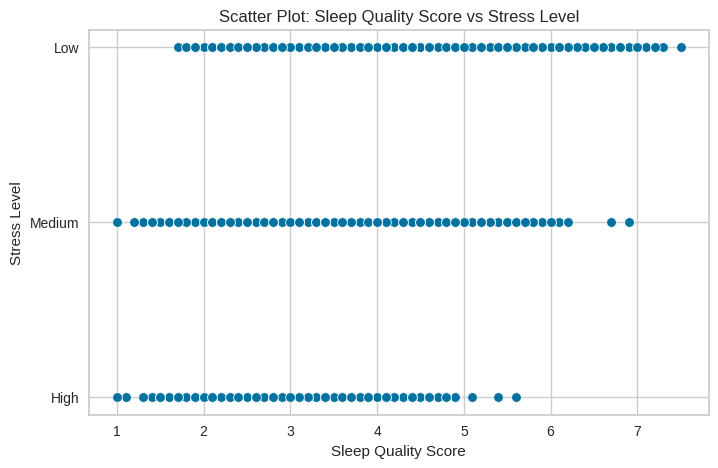

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Sleep_Quality_Score'], y=df['Daily_Stress_Level'])
plt.title('Scatter Plot: Sleep Quality Score vs Stress Level')
plt.xlabel('Sleep Quality Score')
plt.ylabel('Stress Level')
plt.show()

**Interpretation:** The scatter plot shows that sleep quality scores vary across stress levels, with high stress becoming less frequent at higher sleep quality scores.
This indicates that normalization is suitable, since sleep quality scores are on a smaller scale than attributes like daily steps.

##Bar Plot

A bar plot compares the average value of a variable across different categories. It helps us see differences or similarities between groups.

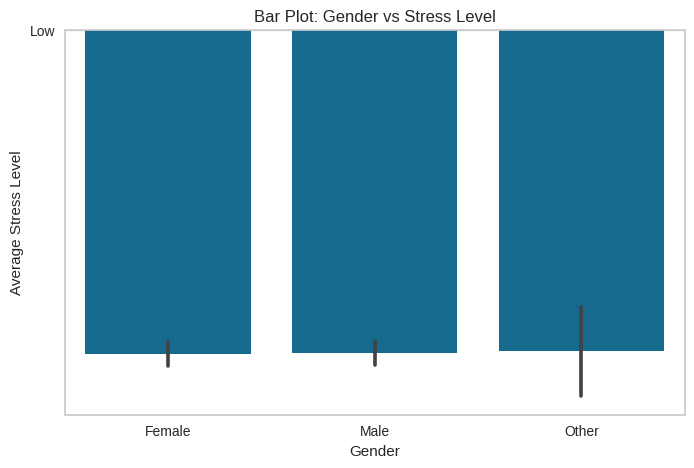

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=df['Gender'], y=df['Daily_Stress_Level'])
plt.title('Bar Plot: Gender vs Stress Level')
plt.xlabel('Gender')
plt.ylabel('Average Stress Level')
plt.show()

**Interpretation:**  
The average stress level is almost the same for all gender groups. This means gender does not play an important role in determining stress level in this dataset.

##Countplot

A countplot shows how many observations fall into each category. It is useful for checking whether the dataset is balanced or imbalanced.

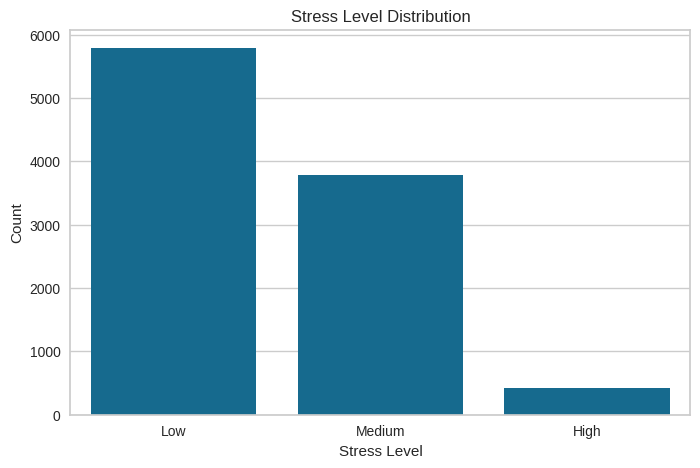

,count
Daily_Stress_Level,
Low,5789
Medium,3786
High,425


In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x=df['Daily_Stress_Level'])
plt.title('Stress Level Distribution')
plt.xlabel('Stress Level')
plt.ylabel('Count')
plt.show()
df['Daily_Stress_Level'].value_counts()

**Interpretation:** Low stress is the most common category, followed by Medium. High stress is very rare. This imbalance shows that the dataset is dominated by lower stress levels, which may influence analysis and model performance.

## Missing-value analysis

In [ ]:
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_analysis = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percentage
})

missing_analysis

,Missing Values,Percentage (%)
User_ID,0,0.00
Age,0,0.00
Gender,0,0.00
Physical_Activity_Level,0,0.00
Diet_Type,0,0.00
BMI,210,2.10
Caffeine_Intake_mg,206,2.06
Water_Intake_liters,0,0.00
Screen_Time_Hours,0,0.00
Daily_Steps,0,0.00


In [ ]:
# Examine columns with missing values
missing_columns = df.columns[df.isnull().any()]

df[missing_columns].describe()

,BMI,Caffeine_Intake_mg,Resting_Heart_Rate,Daily_Sleep_Hours
count,9790.000000,9794.000000,9781.000000,9810.000000
mean,25.087406,207.365224,66.944177,6.957951
std,3.905276,137.681368,8.450527,0.907726
min,17.500000,0.000000,50.000000,3.500000
25%,22.300000,100.000000,61.000000,6.300000
50%,25.100000,201.000000,67.000000,7.000000
75%,27.800000,303.000000,73.000000,7.600000
max,38.000000,730.000000,95.000000,10.900000


In [ ]:
 #Check skewness of columns with missing values
df[missing_columns].skew()

,0
BMI,0.151747
Caffeine_Intake_mg,0.338752
Resting_Heart_Rate,-0.022946
Daily_Sleep_Hours,0.030105


### Missing Values Analysis Interpretation

The missing-value analysis showed that four attributes contained missing values: BMI (2.10%), Caffeine_Intake_mg (2.06%), Resting_Heart_Rate (2.19%), and Daily_Sleep_Hours (1.90%).

The skewness values were 0.1517, 0.3388, -0.0229, and 0.0301, respectively. These values indicate approximately symmetric distributions with relatively low skewness. Therefore, mean imputation was considered an appropriate method for handling the missing values.

# **[4] Data Preprocessing**

In Phase 2 the data was preprocessed. Missing values (825 in total) were replaced using mean imputation, the User_ID attribute was removed, the numerical attributes were normalized using Min-Max scaling, and the categorical attributes were converted to numerical values. The resulting dataset contains 10,000 records and 15 attributes with no missing values, and it was saved as Preprocessed_dataset.csv.

### **Preprocessing Technique #1: Mean Imputation**

In [ ]:
df_preprocessed = df.copy()

for column in missing_columns:
    df_preprocessed[column] = df_preprocessed[column].fillna(
        df_preprocessed[column].mean()
    )

# Check missing values after preprocessing
df_preprocessed[missing_columns].isnull().sum()

,0
BMI,0
Caffeine_Intake_mg,0
Resting_Heart_Rate,0
Daily_Sleep_Hours,0


In [ ]:
# Compare missing values before and after preprocessing

comparison = pd.DataFrame({
    'Before': df[missing_columns].isnull().sum(),
    'After': df_preprocessed[missing_columns].isnull().sum()
})

comparison

,Before,After
BMI,210,0
Caffeine_Intake_mg,206,0
Resting_Heart_Rate,219,0
Daily_Sleep_Hours,190,0


Mean Imputation: Mean imputation was chosen due to the minimal skewness and symmetry of the numerical features with missing values (BMI, Caffeine_Intake_mg, Resting_Heart_Rate, and Daily_Sleep_Hours). The missing values were then replaced with the mean values of those variables. This allows the preservation of all records in the dataset as well as the generation of adequate numerical values for the missing values. As a result, there are no missing values in any of those four attributes.

### **User identifier removal**

In [ ]:
df_preprocessed = df_preprocessed.drop(columns=['User_ID'])

User_ID is an identifier and does not provide useful information for the analysis. It was removed from the dataset, which reduced the number of attributes from 16 to 15 and prevented the identifier from being used in the data mining process.

### **Preprocessing Technique #2: Normalization through Min-Max Scaling**

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_preprocessed[numeric_columns] = scaler.fit_transform(df_preprocessed[numeric_columns])

df_preprocessed.head()

,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,Female,Low,Healthy,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,Low
1,1.000000,Male,Low,Average,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,Low
2,0.549020,Male,Low,Average,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,Medium
3,0.274510,Female,Medium,Healthy,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,Low
4,0.823529,Male,Medium,Unhealthy,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,Low


The statistical summary and boxplots showed that the numerical attributes have very different value ranges.

For example, Daily_Steps ranged up to 23,451, while Water_Intake_liters ranged only up to 5.

This can cause attributes with larger values to have a greater influence in distance-based algorithms such as K-Means. Min-Max normalization was applied to the numerical attributes to scale their values to a range between 0 and 1, making them more comparable and suitable for the data mining algorithms.

### **Preprocessing Technique #3: Data Conversion through Label Encoding and Categorical Mapping**

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df_preprocessed['Gender'] = le.fit_transform(df_preprocessed['Gender'])
df_preprocessed['Physical_Activity_Level'] = df_preprocessed['Physical_Activity_Level'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2})

df_preprocessed['Diet_Type'] = df_preprocessed['Diet_Type'].map({
    'Unhealthy': 0,
    'Average': 1,
    'Healthy': 2})

df_preprocessed['Daily_Stress_Level'] = df_preprocessed['Daily_Stress_Level'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2})

df_preprocessed.head()

,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,0
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,0
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,1
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,0
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,0


Gender, Physical_Activity_Level, Diet_Type, and Daily_Stress_Level are stored as text, and categorical attributes cannot be directly used in numerical data mining algorithms. Physical Activity Level, Diet Type, and Daily Stress Level have a natural order (for example, Low, Medium, High), so they were converted using predefined numerical mappings to keep that order, since Label Encoding assigns numbers alphabetically and would have broken it. Gender has no natural order, so it was converted using Label Encoding.

### **Raw and Preprocessed Datasets Comparison:**

In [ ]:
comparison = pd.DataFrame(
    {
    '': ['Number of Records',
         'Number of Attributes',
         'Missing Values', 'Numerical Attributes', 'Categorical Attributes'],

    'Raw Dataset': [df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        'Original scale',
        'Text'],
    'Preprocessed Dataset':[
        df_preprocessed.shape[0],
        df_preprocessed.shape[1],
        df_preprocessed.isnull().sum().sum(),
        'Normalized (0–1)',
        'Converted to numerical values']
    })

display(comparison)

print("Raw Dataset")
display(df.head())

print("Preprocessed Dataset")
display(df_preprocessed.head())

,,Raw Dataset,Preprocessed Dataset
0,Number of Records,10000,10000
1,Number of Attributes,16,15
2,Missing Values,825,0
3,Numerical Attributes,Original scale,Normalized (0–1)
4,Categorical Attributes,Text,Converted to numerical values


Raw Dataset


,User_ID,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,U00001,56,Female,Low,Healthy,25.1,99.0,1.6,3.9,4731,1697,74.0,6.6,1.5,4.0,Low
1,U00002,69,Male,Low,Average,25.8,104.0,2.2,3.9,4440,1377,70.0,8.0,2.4,5.3,Low
2,U00003,46,Male,Low,Average,24.0,188.0,1.4,5.5,5023,1289,72.0,8.2,1.9,5.0,Medium
3,U00004,32,Female,Medium,Healthy,25.5,124.0,3.1,9.8,6082,1683,69.0,7.4,2.5,3.9,Low
4,U00005,60,Male,Medium,Unhealthy,NaN,0.0,2.4,5.3,7285,1621,73.0,7.9,2.2,5.2,Low


Preprocessed Dataset


,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,0
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,0
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,1
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,0
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,0


In [ ]:
# Save the preprocessed dataset separately
output_path = "Preprocessed_dataset.csv"

df_preprocessed.to_csv(output_path, index=False)

print("Preprocessed dataset saved successfully.")

Preprocessed dataset saved successfully.


### Overall:
Missing values were handled using mean imputation, reducing the total number of missing values from 825 to 0. The User_ID attribute was removed because it is only an identifier, the numerical attributes were normalized to a range of 0 to 1, and the categorical attributes were converted into numerical values. The outliers found in the boxplots were kept, since they represent realistic values (for example, very active people with high step counts) rather than errors. The resulting dataset contains 10,000 records and 15 attributes with no missing values, all of them numerical, so it can be used directly by the Decision Tree and K-Means algorithms. It was saved separately as Preprocessed_dataset.csv.

# **[5] Data Mining Technique**

For classification, a Decision Tree classifier (DecisionTreeClassifier from sklearn.tree) was applied to predict Daily_Stress_Level from the wearable and lifestyle attributes. The data was split using train_test_split from sklearn.model_selection (with stratify to keep the class proportions). Two attribute selection measures were compared, Entropy (Information Gain) and Gini Index, using three train/test partitions (90/10, 80/20, and 70/30). Decision trees were chosen because they are easy to interpret and show which attributes (e.g., screen time, caffeine intake, physical activity) contribute most to the prediction. Because the High stress class has very few records, the models were evaluated before and after merging High with Medium. The results were evaluated using accuracy, error rate, recall, and confusion matrices (ConfusionMatrixDisplay from sklearn.metrics). The final tree was visualized using plot_tree from sklearn.tree.

For clustering, K-Means (KMeans from sklearn.cluster) was applied to the predictor attributes after standardizing them with StandardScaler from sklearn.preprocessing. The clustering process was performed without using the class label, allowing individuals with similar characteristics to be grouped together. Three values of K (2, 3, and 4) were evaluated, and the optimal number of clusters was selected by majority rule using the Elbow Method (total within-cluster sum of squares), the average Silhouette coefficient (silhouette_score from sklearn.metrics), and the Calinski-Harabasz index (calinski_harabasz_score from sklearn.metrics), with Yellowbrick used to visualize the silhouette plots.

Pandas and NumPy were used for data handling, and Matplotlib and Seaborn for visualization.

# **[6] Evaluation and Comparison**

### Import Libraries & Load Preprocessed Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import classification_report

url= "https://raw.githubusercontent.com/hend-22/-IT326-Project/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)
df.head()


,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,0
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,0
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,1
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,0
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,0


##Classification - Evaluation and Comparison

In this section, the performance of the classification techniques applied to the Daily Stress Level dataset is evaluated and compared using Entropy (Information Gain) and Gini. The models are tested using different training and testing partitions (90/10, 80/20, and 70/30), and their performance is assessed using accuracy, recall, and confusion matrices.

## Feature Selection

In this step, the input features and target variable were defined. All dataset attributes, except the class attribute (Daily_Stress_Level), were selected as predictor variables (X). The Daily_Stress_Level attribute was selected as the target variable (y) for the classification task.

In [ ]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

##Visual Representation

Confusion matrices were generated for each partition size to visually evaluate the classifier's performance and to examine the distribution of correct and incorrect predictions before and after class merging. These visualizations helped interpret the model's behavior and assess the effectiveness of the classification process.

### Gini Decision Tree Classification

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop('Daily_Stress_Level', axis=1)
y = df['Daily_Stress_Level']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.1,
    random_state=1,
    stratify=y
)

gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model.fit(X_train, y_train)

print("Gini Decision Tree trained successfully!")

Gini Decision Tree trained successfully!


### Gini Decision Tree – 90/10 Split


Using the Gini criterion with a 90/10 train-test split, the model achieved **65.8% accuracy**. The confusion matrix shows that the model correctly classified **435 Low, 212 Medium, and 11 High** stress cases. However, it identified only **11 out of 42** actual High stress cases (26.2%), showing that the model had difficulty predicting this class.

Gini Decision Tree - 90/10 Split
              precision    recall  f1-score   support

           0       0.75      0.75      0.75       579
           1       0.56      0.56      0.56       379
           2       0.26      0.26      0.26        42

    accuracy                           0.66      1000
   macro avg       0.52      0.52      0.52      1000
weighted avg       0.66      0.66      0.66      1000



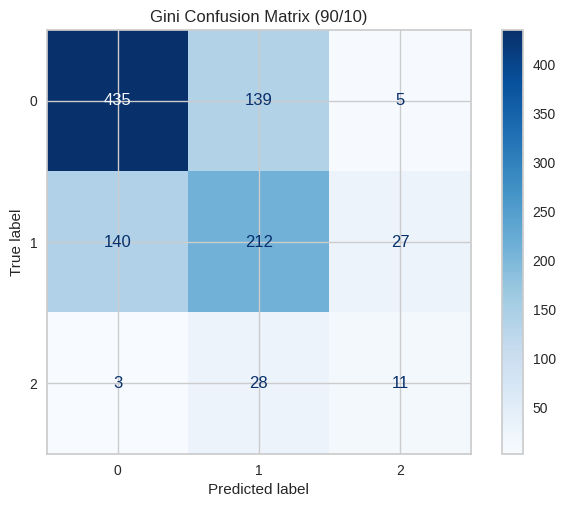

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = gini_model.predict(X_test)



print("Gini Decision Tree - 90/10 Split")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (90/10)")
plt.show()

### Gini Decision Tree – 80/20 Split

Using the Gini criterion with an 80/20 train-test split, the model achieved **65.2% accuracy**. The confusion matrix shows that 862 Low, 417 Medium, and 25 High stress cases were correctly classified. However, only 25 out of 85 actual High stress cases were identified, showing that the model still struggled with this class. The accuracy was also slightly lower than the 90/10 split.

Gini Decision Tree - 80/20 Split
              precision    recall  f1-score   support

           0       0.75      0.74      0.75      1158
           1       0.55      0.55      0.55       757
           2       0.27      0.29      0.28        85

    accuracy                           0.65      2000
   macro avg       0.52      0.53      0.53      2000
weighted avg       0.65      0.65      0.65      2000



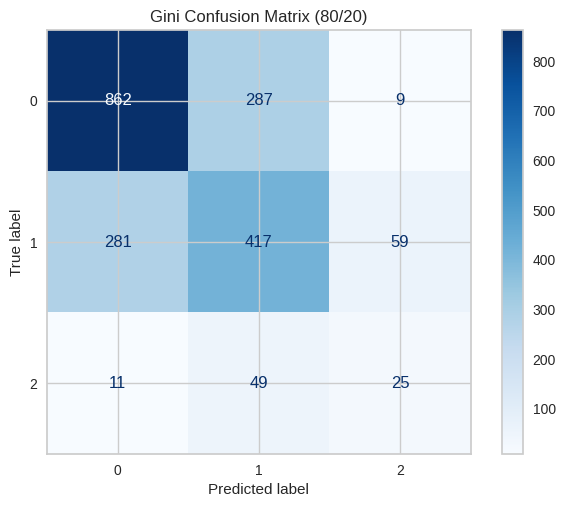

In [ ]:
# Gini Decision Tree - 80/20 Split

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

gini_model_80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model_80.fit(X_train_80, y_train_80)

y_pred_80 = gini_model_80.predict(X_test_80)

print("Gini Decision Tree - 80/20 Split")
print(classification_report(
    y_test_80,
    y_pred_80,
    zero_division=0
))



cm_80 = confusion_matrix(y_test_80, y_pred_80)

ConfusionMatrixDisplay(
    confusion_matrix=cm_80,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (80/20)")
plt.show()

### Gini Decision Tree – 70/30 Split
Using the Gini criterion with a 70/30 split, the model achieved **65.6% accuracy**. It correctly classified 1,316 Low, 610 Medium, and 42 High stress cases. However, only 42 out of 127 High stress cases were correctly identified (33.1%), showing that the model still struggles with this class.

Gini Decision Tree - 70/30 Split
              precision    recall  f1-score   support

           0       0.74      0.76      0.75      1737
           1       0.57      0.54      0.55      1136
           2       0.29      0.33      0.31       127

    accuracy                           0.66      3000
   macro avg       0.53      0.54      0.54      3000
weighted avg       0.66      0.66      0.66      3000



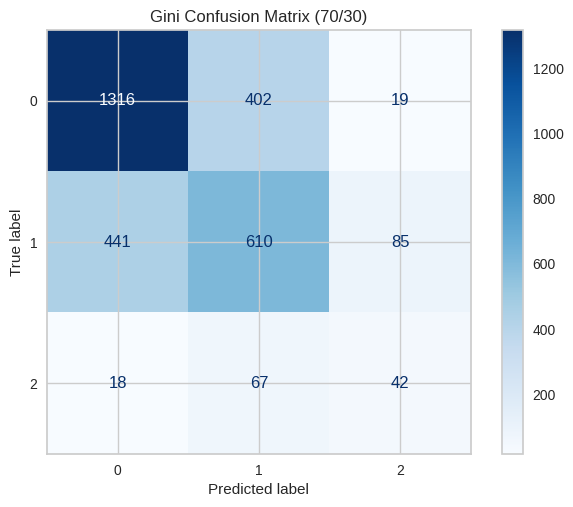

In [ ]:
# Gini Decision Tree - 70/30 Split

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X, y,
    test_size=0.3,
    random_state=1,
    stratify=y
)

gini_model_70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model_70.fit(X_train_70, y_train_70)

y_pred_70 = gini_model_70.predict(X_test_70)

print("Gini Decision Tree - 70/30 Split")
print(classification_report(
    y_test_70,
    y_pred_70,
    zero_division=0
))



cm_70 = confusion_matrix(y_test_70, y_pred_70)

ConfusionMatrixDisplay(
    confusion_matrix=cm_70,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (70/30)")
plt.show()

### Gini Decision Tree – Results

The Gini Decision Tree was tested using three train-test splits to compare its performance.

| Train/Test Split | Accuracy | High Stress Recall |
|---|---|---|
| 90/10 | 65.80% | 26.2% |
| 80/20 | 65.2% | 29.4% |
| 70/30 | 65.60% | 33.1% |

The 90/10 split achieved the highest accuracy (65.8%), while the 70/30 split had a slightly lower accuracy (65.6%). All three splits showed difficulty identifying High stress cases, which may be related to the small number of samples in this class.

###Entropy Decision Tree Classification
The Decision Tree classifier was applied to the dataset using the Entropy criterion (Information Gain) with three different train-test partitions:

90% Training  10% Testing

80% Training  20% Testing

70% Training  30% Testing


###Entropy Decision Tree – 90/10 Split


Entropy Decision Tree - 90/10 Split
              precision    recall  f1-score   support

           0       0.75      0.76      0.76       579
           1       0.57      0.58      0.57       379
           2       0.31      0.26      0.28        42

    accuracy                           0.67      1000
   macro avg       0.54      0.53      0.54      1000
weighted avg       0.67      0.67      0.67      1000



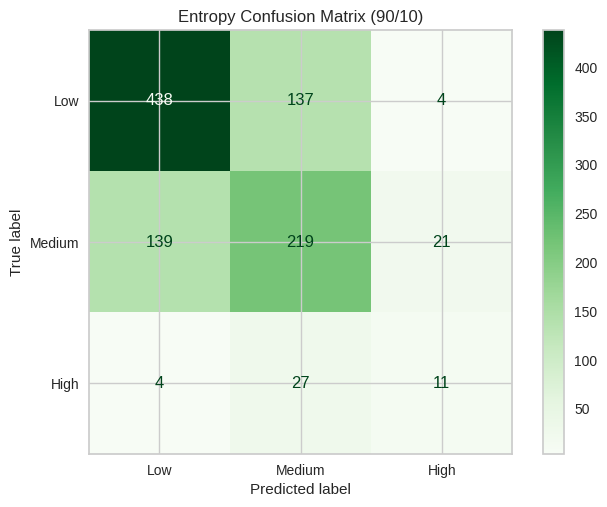

In [ ]:
X_train_e9, X_test_e9, y_train_e9, y_test_e9 = train_test_split(X,y,test_size=0.1,random_state=1,stratify=y)

clf_e9=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf_e9.fit(X_train_e9,y_train_e9)
y_pred_e9=clf_e9.predict(X_test_e9)

print("Entropy Decision Tree - 90/10 Split")
print(classification_report(
    y_test_e9,
    y_pred_e9,
    zero_division=0
))

labels = ["Low", "Medium","High"]
cm_e9 = confusion_matrix(y_test_e9, y_pred_e9)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e9,
    display_labels=labels
)

disp.plot(cmap="Greens")


plt.title("Entropy Confusion Matrix (90/10)")
plt.show()

Using the Entropy criterion with a 90/10 split, the model achieved 66.8% accuracy. It performed best in identifying Class 0, while Class 2 had the lowest recall.

###Entropy Decision Tree – 80/20 Split


Entropy Decision Tree - 80/20 Split
              precision    recall  f1-score   support

           0       0.76      0.73      0.75      1158
           1       0.56      0.59      0.57       757
           2       0.30      0.35      0.33        85

    accuracy                           0.66      2000
   macro avg       0.54      0.56      0.55      2000
weighted avg       0.67      0.66      0.66      2000



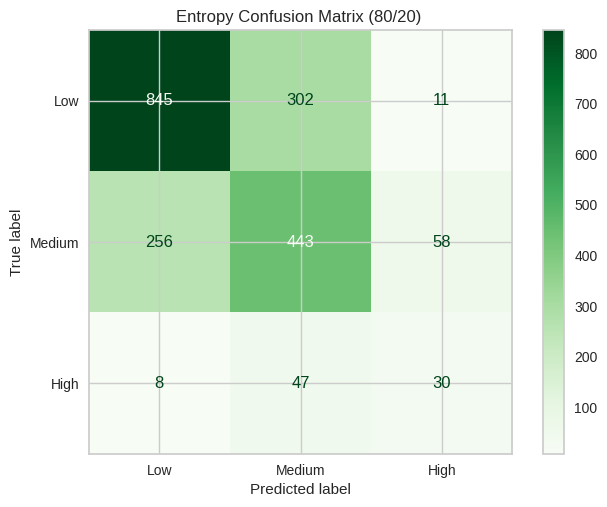

In [ ]:
X_train_e8, X_test_e8, y_train_e8, y_test_e8 = train_test_split(X,y,test_size=0.2,random_state=1,stratify=y)

clf_e8=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf_e8.fit(X_train_e8,y_train_e8)
y_pred_e8=clf_e8.predict(X_test_e8)

print("Entropy Decision Tree - 80/20 Split")
print(classification_report(
    y_test_e8,
    y_pred_e8,
    zero_division=0
))

labels = ["Low", "Medium","High"]
cm_e8 = confusion_matrix(y_test_e8, y_pred_e8)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e8,
    display_labels=labels
)

disp.plot(cmap="Greens")

plt.title("Entropy Confusion Matrix (80/20) ")
plt.show()

Using the Entropy criterion with a 80/20 split, the model achieved 65.9% accuracy.

 Class 2 remained the most difficult class to identify correctly with recall 35.3%.

###Entropy Decision Tree – 70/30 Split



Entropy Decision Tree - 70/20 Split
              precision    recall  f1-score   support

           0       0.74      0.74      0.74      1737
           1       0.55      0.55      0.55      1136
           2       0.29      0.30      0.29       127

    accuracy                           0.65      3000
   macro avg       0.53      0.53      0.53      3000
weighted avg       0.65      0.65      0.65      3000



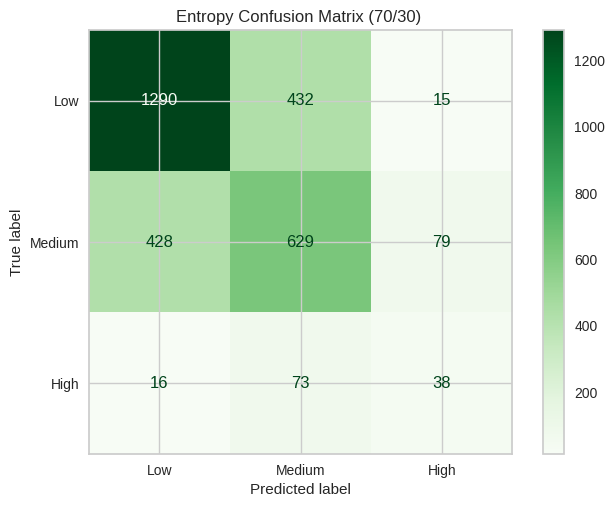

In [ ]:

X_train_e7, X_test_e7, y_train_e7, y_test_e7 = train_test_split(X,y,test_size=0.3,random_state=1,stratify=y)

clf_e7=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf_e7.fit(X_train_e7,y_train_e7)
y_pred_e7=clf_e7.predict(X_test_e7)

print("Entropy Decision Tree - 70/20 Split")
print(classification_report(
    y_test_e7,
    y_pred_e7,
    zero_division=0
))

cn=df['Daily_Stress_Level'].unique()

labels = ["Low", "Medium","High"]
cm_e7= confusion_matrix(y_test_e7, y_pred_e7)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e7,
    display_labels=labels
)

disp.plot(cmap="Greens")

plt.title("Entropy Confusion Matrix (70/30) ")
plt.show()

Using the Entropy criterion with a 70/30 split, the model achieved 65.2% accuracy.

 The model maintained good recall 74.2% for Class 0 but struggled with Class 2 having 29.9% recall.

### Entropy Decision Tree – Results

The Entropy Decision Tree was tested using three train-test splits to compare its performance.


| Train/Test Split | Accuracy | High Stress Recall |
|---|---|---|
| 90/10 | 66.8% | 26.19% |
| 80/20 | 65.9% | 35.3% |
| 70/30 | 65.2% | 29.9% |


**Results Discussion :**

The Decision Tree classifier using the Entropy criterion was evaluated with three partition sizes: 90/10, 80/20, and 70/30. The accuracy decreased slightly from 66.8% to 65.9% and 65.2% as the partition size changed. Recall was consistently highest for Class 0 (72.97%-75.6%), moderate for Class 1 (55.4%-58.5%), and lowest for Class 2 (26.2%-35.3%), indicating that the model had difficulty identifying Class 2. Overall, the 90/10 partition achieved the best performance.

## **Class Merging**

Since Class 2 achieved the lowest recall across all train-test splits, this means that the model had difficulty correctly identifying samples belonging to this class. Therefore, Class 2 was merged with Class 1 to reduce class imbalance and simplify the classification task.

In [ ]:
df['Daily_Stress_Level'] = df['Daily_Stress_Level'].replace({2:1})
df['Daily_Stress_Level'].value_counts()

,count
Daily_Stress_Level,
0,5789
1,4211


In [ ]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

###Gini Decision Tree After Merging High and Medium

In [ ]:
# copy used by the models after merging
#df already contains the merged classes (0=Low, 1=Medium + High)
df_binary = df.copy()

print(df_binary['Daily_Stress_Level'].value_counts())

Daily_Stress_Level
0    5789
1    4211
Name: count, dtype: int64


Gini Decision Tree - 90/10 Split
              precision    recall  f1-score   support

           0       0.76      0.76      0.76       579
           1       0.67      0.66      0.66       421

    accuracy                           0.72      1000
   macro avg       0.71      0.71      0.71      1000
weighted avg       0.72      0.72      0.72      1000



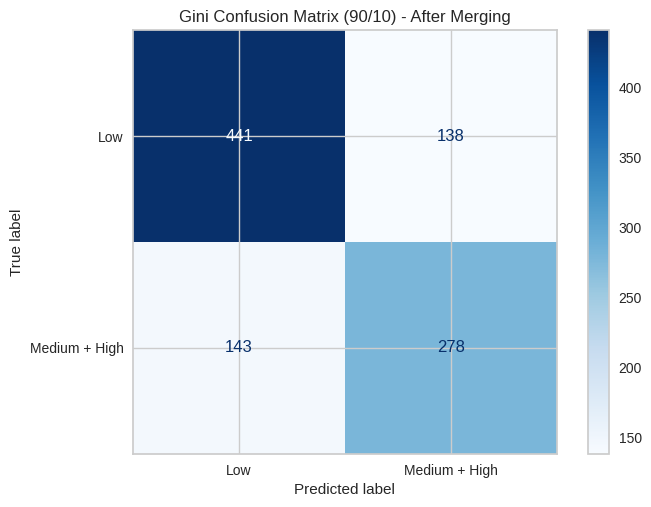

In [ ]:
# Gini Decision Tree - 90/10 Split (After Merging)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_binary = df_binary.drop('Daily_Stress_Level', axis=1)
y_binary = df_binary['Daily_Stress_Level']

X_train_b90, X_test_b90, y_train_b90, y_test_b90 = train_test_split(
    X_binary, y_binary,
    test_size=0.1,
    random_state=1,
    stratify=y_binary
)

gini_b90 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b90.fit(X_train_b90, y_train_b90)

y_pred_b90 = gini_b90.predict(X_test_b90)

print("Gini Decision Tree - 90/10 Split")
print(classification_report(
    y_test_b90,
    y_pred_b90,
    zero_division=0
))

cm_b90 = confusion_matrix(y_test_b90, y_pred_b90, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b90,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (90/10) - After Merging")
plt.show()

The Gini Decision Tree achieved 71.9% accuracy using the 90/10 split after merging Medium and High stress levels. The model correctly classified 441 Low and 278 Medium + High cases, but some predictions were still incorrect.

Gini Decision Tree - 80/20 Split
              precision    recall  f1-score   support

           0       0.75      0.72      0.73      1158
           1       0.63      0.67      0.65       842

    accuracy                           0.70      2000
   macro avg       0.69      0.69      0.69      2000
weighted avg       0.70      0.70      0.70      2000



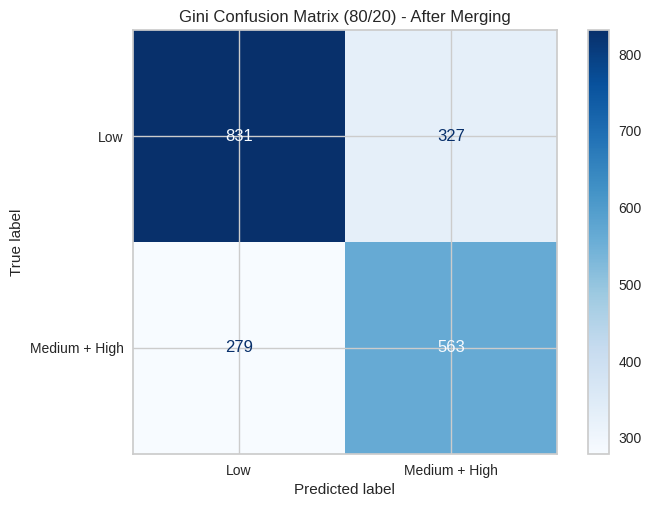

In [ ]:
# Gini Decision Tree - 80/20 Split (After Merging)

X_train_b80, X_test_b80, y_train_b80, y_test_b80 = train_test_split(
    X_binary, y_binary,
    test_size=0.2,
    random_state=1,
    stratify=y_binary
)

gini_b80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b80.fit(X_train_b80, y_train_b80)

y_pred_b80 = gini_b80.predict(X_test_b80)

print("Gini Decision Tree - 80/20 Split")
print(classification_report(
    y_test_b80,
    y_pred_b80,
    zero_division=0
))

cm_b80 = confusion_matrix(y_test_b80, y_pred_b80, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b80,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (80/20) - After Merging")
plt.show()

The Gini Decision Tree achieved **69.7% accuracy** using the 80/20 split after merging Medium and High stress levels. The model correctly classified 831 Low and 563 Medium + High cases, but some cases were still misclassified. The accuracy was slightly lower than the 90/10 split.

Gini Decision Tree - 70/30 Split
              precision    recall  f1-score   support

           0       0.74      0.74      0.74      1737
           1       0.64      0.64      0.64      1263

    accuracy                           0.70      3000
   macro avg       0.69      0.69      0.69      3000
weighted avg       0.70      0.70      0.70      3000



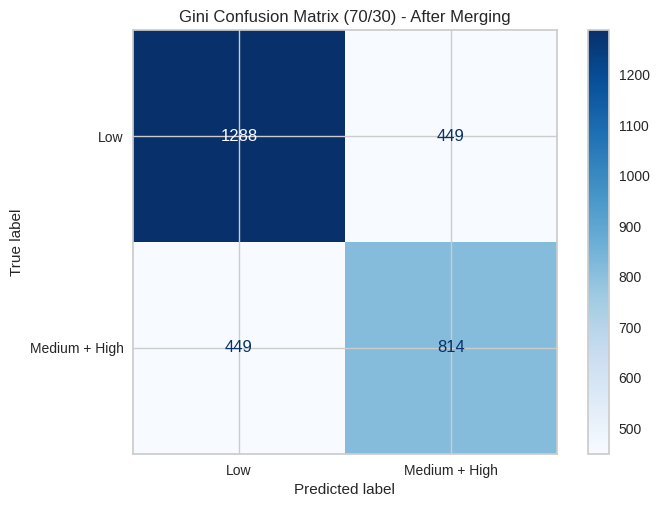

In [ ]:
# Gini Decision Tree - 70/30 Split (After Merging)

X_train_b70, X_test_b70, y_train_b70, y_test_b70 = train_test_split(
    X_binary, y_binary,
    test_size=0.3,
    random_state=1,
    stratify=y_binary
)

gini_b70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b70.fit(X_train_b70, y_train_b70)

y_pred_b70 = gini_b70.predict(X_test_b70)

print("Gini Decision Tree - 70/30 Split")
print(classification_report(
    y_test_b70,
    y_pred_b70,
    zero_division=0
))

cm_b70 = confusion_matrix(y_test_b70, y_pred_b70, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b70,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (70/30) - After Merging")
plt.show()

The Gini Decision Tree achieved **70.07% accuracy** using the 70/30 train-test split after merging Medium and High stress levels. The model correctly classified 1,288 Low and 814 Medium + High cases. However, 449 Medium + High cases were incorrectly predicted as Low. The accuracy was higher than the 80/20 split (69.7%) but lower than the 90/10 split (71.9%).

### Gini Decision Tree Comparison Before and After Merging

| Train/Test Split | Before Merging | After Merging |
|---|---|---|
| 90/10 | 65.80% | 71.90% |
| 80/20 | 65.20% | 69.70% |
| 70/30 | 65.60% | 70.07% |

**Average Accuracy Before Merging:** 65.53%

**Average Accuracy After Merging:** 70.56%

**Improvement:** Approximately 5.03 percentage points.

### Analysis and Interpretation

The results show an improvement in overall accuracy after merging Medium and High stress levels into one class.

The average accuracy increased from 65.53% to 70.56%, representing an improvement of approximately 5.03 percentage points.

The 90/10 split achieved the highest accuracy (71.90%) after merging, followed by the 70/30 split (70.07%) and the 80/20 split (69.70%).

This improvement suggests that reducing the number of classes made the classification task easier. However, some Medium + High stress cases were still incorrectly classified as Low, indicating that the model continues to have classification limitations.

### Entropy Decision Tree After Merging High and Medium
The same Decision Tree classifier using the Entropy criterion was applied after merging Class 2 with Class 1 using the same train-test partitions.


###Entropy Decision Tree – 90/10 Split **After Merging**



Entropy Decision Tree - 90/10 Split
              precision    recall  f1-score   support

           0       0.77      0.76      0.77       579
           1       0.68      0.69      0.68       421

    accuracy                           0.73      1000
   macro avg       0.72      0.73      0.72      1000
weighted avg       0.73      0.73      0.73      1000



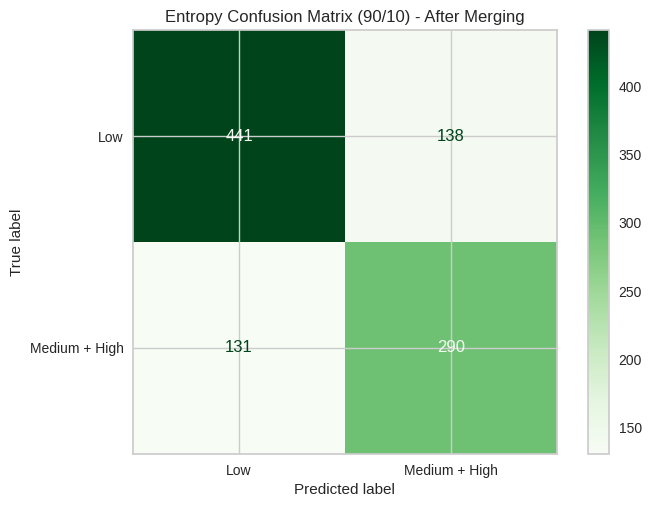

In [ ]:
X_train_e90, X_test_e90, y_train_e90, y_test_e90 = train_test_split(X_binary,y_binary,test_size=0.1,random_state=1,stratify=y_binary)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf.fit(X_train_e90,y_train_e90)
y_pred_e90=clf.predict(X_test_e90)

print("Entropy Decision Tree - 90/10 Split")
print(classification_report(
    y_test_e90,
    y_pred_e90,
    zero_division=0
))

labels = ["Low", "Medium + High"]
cm_e90= confusion_matrix(y_test_e90, y_pred_e90)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e90,
    display_labels=labels
)

disp.plot(cmap="Greens")


plt.title("Entropy Confusion Matrix (90/10) - After Merging")
plt.show()

Using the Entropy criterion with a 90/10 split after class merging, the model achieved 73.1% accuracy. It correctly identified 76.1% of Class 0 cases and 68.9% of Class 1 cases, showing good performance across both classes.


###Entropy Decision Tree – 80/20 Split **After Merging**



Entropy Decision Tree - 80/20 Split
              precision    recall  f1-score   support

           0       0.77      0.74      0.75      1158
           1       0.66      0.69      0.67       842

    accuracy                           0.72      2000
   macro avg       0.71      0.71      0.71      2000
weighted avg       0.72      0.72      0.72      2000



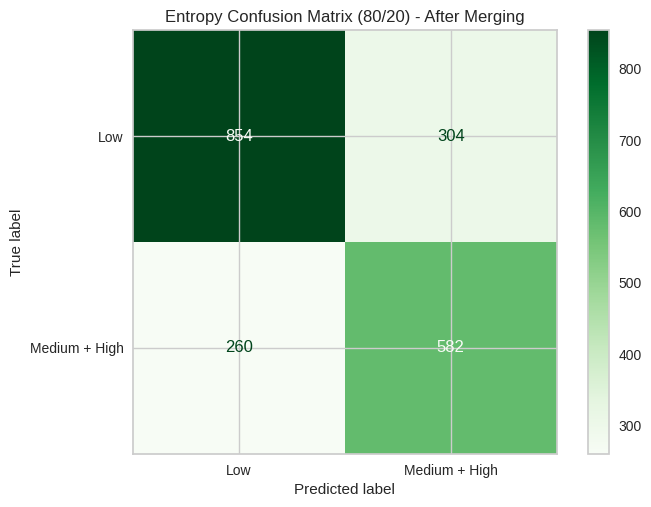

In [ ]:
X_train_e80, X_test_e80, y_train_e80, y_test_e80 = train_test_split(X_binary,y_binary,test_size=0.2,random_state=1,stratify=y_binary)

clf_e80=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf_e80.fit(X_train_e80,y_train_e80)
y_pred_e80=clf_e80.predict(X_test_e80)

print("Entropy Decision Tree - 80/20 Split")
print(classification_report(
    y_test_e80,
    y_pred_e80,
    zero_division=0
))

labels = ["Low", "Medium + High"]
cm_e80 = confusion_matrix(y_test_e80, y_pred_e80)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e80,
    display_labels=labels
)

disp.plot(cmap="Greens")

plt.title("Entropy Confusion Matrix (80/20) - After Merging")
plt.show()

Using the Entropy criterion with an 80/20 split after class merging, the model achieved 71.8% accuracy. The recall values were 73.7% for Class 0 and 69.1% for Class 1, indicating better classification performance than before merging high stress level with medium.

###Entropy Decision Tree – 70/30 Split **After Merging**



Entropy Decision Tree - 70/20 Split
              precision    recall  f1-score   support

           0       0.76      0.73      0.74      1737
           1       0.65      0.68      0.66      1263

    accuracy                           0.71      3000
   macro avg       0.70      0.70      0.70      3000
weighted avg       0.71      0.71      0.71      3000



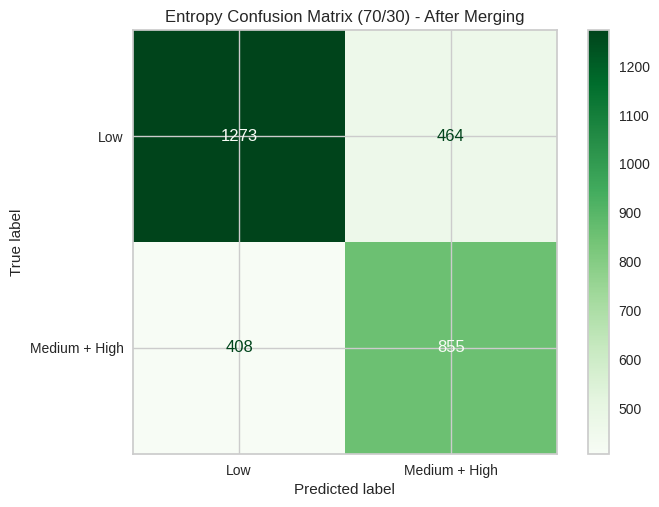

In [ ]:
X_train_e70, X_test_e70, y_train_e70, y_test_e70 = train_test_split(X_binary,y_binary,test_size=0.3,random_state=1,stratify=y_binary)

clf_e70=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf_e70.fit(X_train_e70,y_train_e70)

y_pred_e70=clf_e70.predict(X_test_e70)


print("Entropy Decision Tree - 70/20 Split")
print(classification_report(
    y_test_e70,
    y_pred_e70,
    zero_division=0
))


labels = ["Low", "Medium + High"]
cm_e70 = confusion_matrix(y_test_e70, y_pred_e70)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e70,
    display_labels=labels
)

disp.plot(cmap="Greens")


plt.title("Entropy Confusion Matrix (70/30) - After Merging")
plt.show()

Using the Entropy criterion with a 70/30 split after class merging, the model achieved 70.9% accuracy. It correctly identified 73.3% of Class 0 cases and 67.7% of Class 1 cases, maintaining good performance for both classes.

### **Entropy Results After Merging Classes**


The Entropy Decision Tree was tested using three train-test splits to compare its performance.


| Train/Test Split | Accuracy | Medium + High Stress Recall |
|---|---|---|
| 90/10 | 73.1% | 68.9% |
| 80/20 | 71.8% | 69.1% |
| 70/30 | 70.9% | 67.7% |


**Average Accuracy Before Merging:** 65.97%

**Average Accuracy After Merging:** 71.93%

**Improvement:** Approximately 5.9 percentage points.



**Analysis and Interpretation**

The results show an improvement in overall accuracy after merging Medium and High stress levels into one class.

The average accuracy increased from 65.97% to 71.93%, representing an improvement of approximately 5.9 percentage points.

The 90/10 split achieved the highest accuracy (73.1%) after merging, followed by the 80/20 split (71.8%) and the 70/30 split (70.9%).

This improvement suggests that reducing the number of classes helped simplify the classification task and mitigate the effects of class imbalance. However, some Medium + High stress cases were still incorrectly classified as Low stress, indicating that the model continues to face challenges in accurately distinguishing between stress levels.

##**Performance After Class Merging**

Compared with the original three-class dataset, class merging improved the model's performance. The accuracy increased from 66.8% (best result before merging) to 73.1% after merging, suggesting that reducing class imbalance helped the Decision Tree classifier make more accurate predictions.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Prepare features and merge Medium + High
X = df.drop(columns=["Daily_Stress_Level"])
y = df["Daily_Stress_Level"].replace({2: 1})

# Compare Gini and Entropy
results = []

for train_size in [0.9, 0.8, 0.7]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        train_size=train_size,
        random_state=1,
        stratify=y
    )

    for criterion in ["gini", "entropy"]:
        model = DecisionTreeClassifier(
            criterion=criterion,
            random_state=1
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Criterion": criterion,
            "Partition": f"{round(train_size*100)}/{round((1-train_size)*100)}",
            "Accuracy": accuracy_score(y_test, y_pred)
        })

comparison_df = pd.DataFrame(results)
display(comparison_df)


,Criterion,Partition,Accuracy
0,gini,90/10,0.719000
1,entropy,90/10,0.731000
2,gini,80/20,0.697000
3,entropy,80/20,0.718000
4,gini,70/30,0.700667
5,entropy,70/30,0.709333


**Classification Results Interpretation**

The Decision Tree classifier was evaluated using Gini Index and Entropy across three training/testing partitions: 90/10, 80/20, and 70/30.

Based on the accuracy results, Entropy performed better than Gini for the 90/10, 80/20, and 70/30 partitions.

The highest accuracy was achieved by Entropy with the 90/10 partition (73.1%), while the lowest accuracy was obtained by Gini with the 80/20 partition (69.7%).

Overall, Entropy achieved better classification performance across the three partitions. However, the accuracy differences were relatively small.

In [ ]:
comparison_table = comparison_df.pivot(
    index="Partition",
    columns="Criterion",
    values="Accuracy"
)

comparison_table = comparison_table.reindex(
    ["90/10", "80/20", "70/30"]
)

comparison_table["Best Model"] = comparison_table.apply(
    lambda row: "Tie" if abs(row["gini"] - row["entropy"]) < 1e-10
    else ("Gini" if row["gini"] > row["entropy"] else "Entropy"),
    axis=1
)

display(comparison_table)

Criterion,entropy,gini,Best Model
Partition,,,
90/10,0.731000,0.719000,Entropy
80/20,0.718000,0.697000,Entropy
70/30,0.709333,0.700667,Entropy


GINI - 90/10 Accuracy: 0.7190


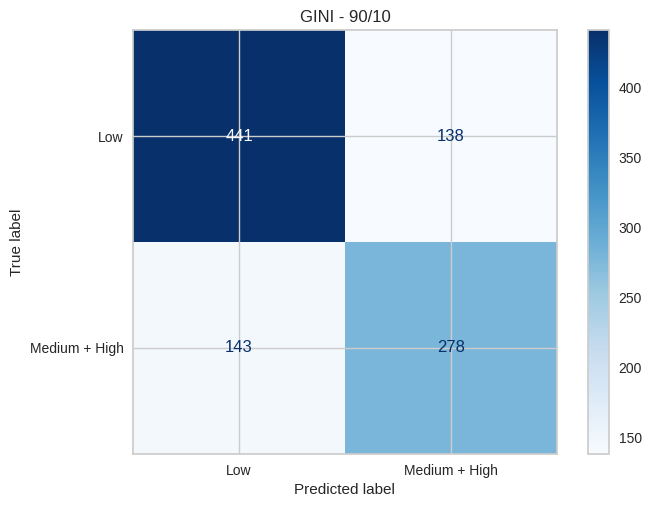

ENTROPY - 90/10 Accuracy: 0.7310


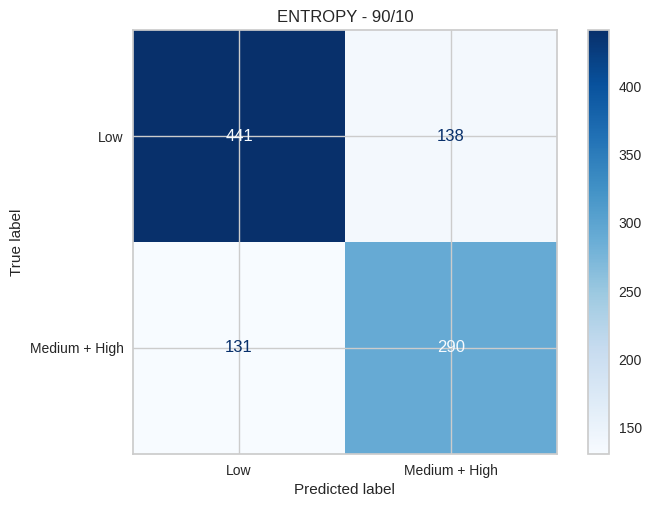

GINI - 80/20 Accuracy: 0.6970


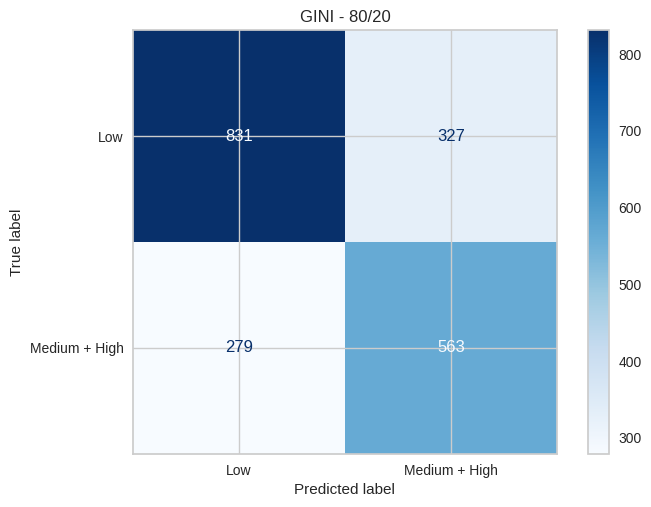

ENTROPY - 80/20 Accuracy: 0.7180


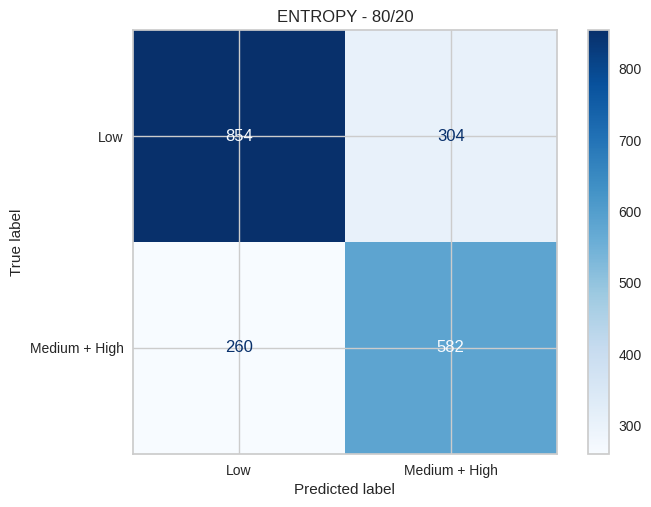

GINI - 70/30 Accuracy: 0.7007


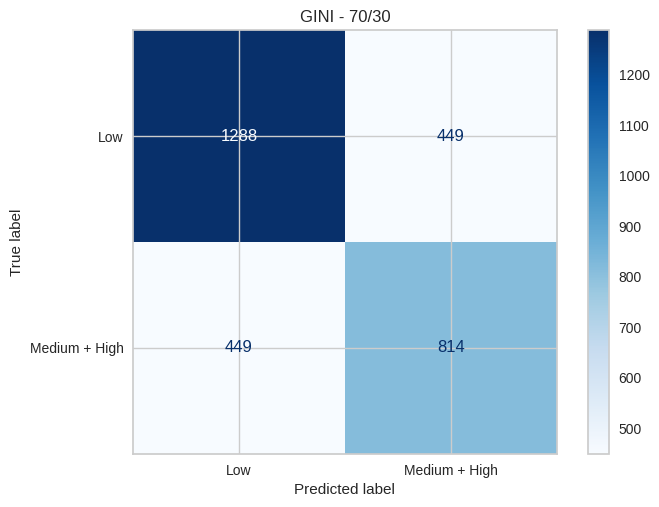

ENTROPY - 70/30 Accuracy: 0.7093


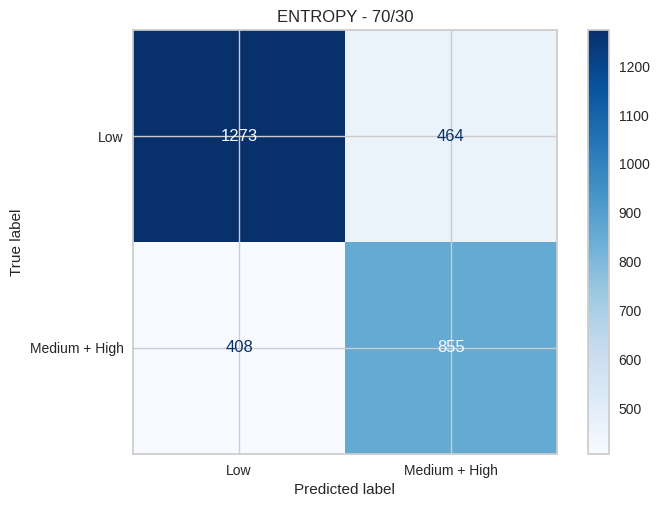

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# Prepare data after merging classes 2 and 1
X = df.drop(columns=["Daily_Stress_Level"])
y = df["Daily_Stress_Level"].replace({2: 1})

# Compare Gini and Entropy
for train_size in [0.9, 0.8, 0.7]:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        train_size=train_size,
        random_state=1,
        stratify=y
    )

    for criterion in ["gini", "entropy"]:

        model = DecisionTreeClassifier(
            criterion=criterion,
            random_state=1
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)

        print(
            f"{criterion.upper()} - "
            f"{round(train_size*100)}/"
            f"{round((1-train_size)*100)} "
            f"Accuracy: {accuracy:.4f}"
        )

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            labels=[0, 1],
            display_labels=["Low", "Medium + High"],
            cmap="Blues",
            values_format="d"
        )

        plt.title(
            f"{criterion.upper()} - "
            f"{round(train_size*100)}/"
            f"{round((1-train_size)*100)}"
        )

        plt.show()


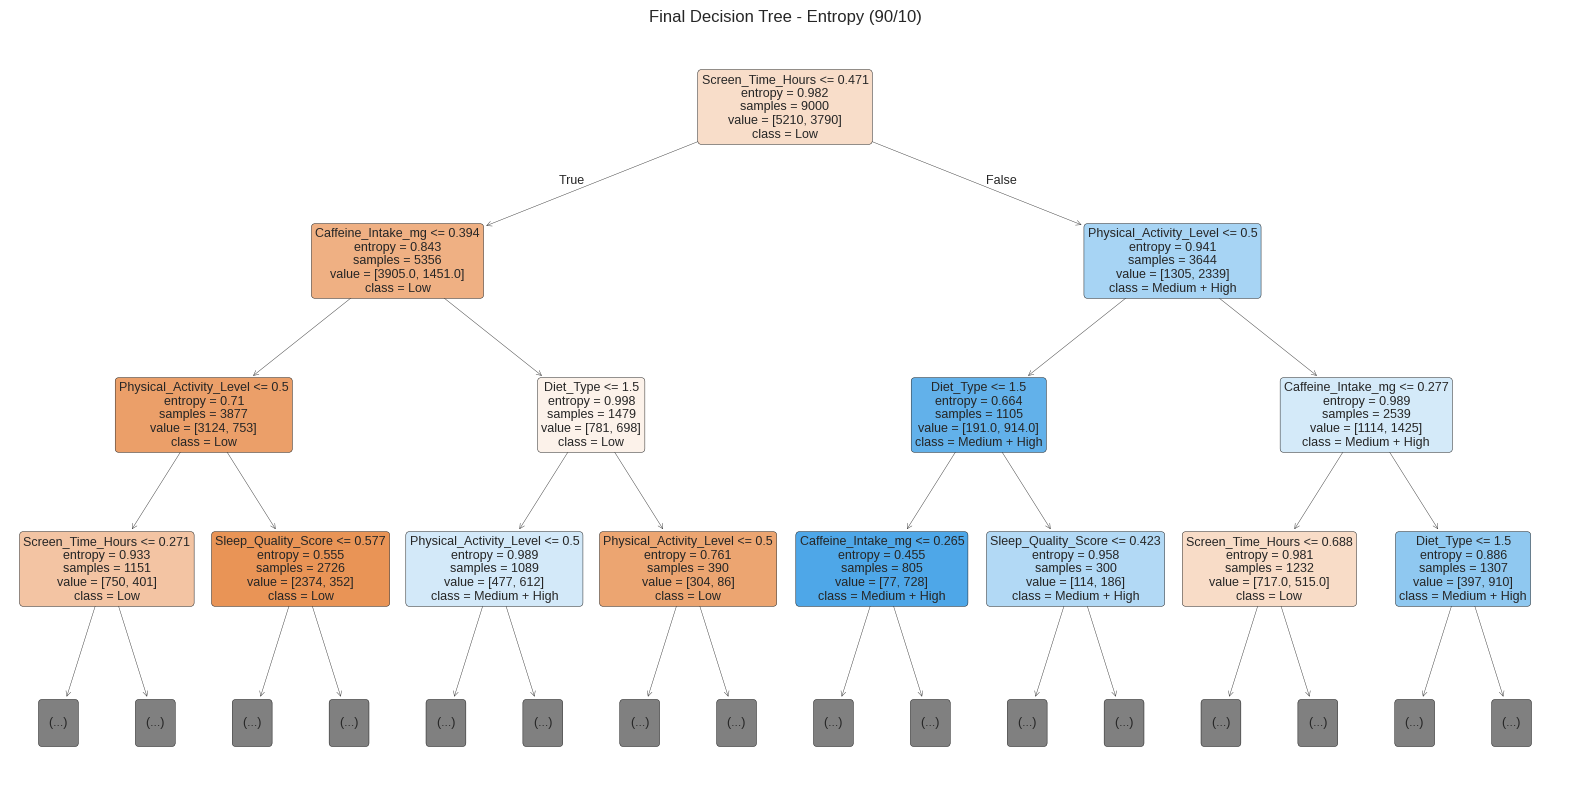

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Use the best-performing configuration: Entropy, 90/10
X = df.drop(columns=["Daily_Stress_Level"])
y = df["Daily_Stress_Level"].replace({2: 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.9,
    random_state=1,
    stratify=y
)

final_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

final_tree.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(
    final_tree,
    feature_names=X.columns,
    class_names=["Low", "Medium + High"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Final Decision Tree - Entropy (90/10)")
plt.show()


**Final Decision Tree Interpretation**

The final Decision Tree model was selected using the Entropy criterion with a 90/10 training/testing partition, as it achieved the highest accuracy of 73.1%.

The root node uses Screen_Time_Hours as the first splitting feature, indicating that screen time is an important factor in the model's classification decisions.

Other features, including Caffeine_Intake_mg, Physical_Activity_Level, Diet_Type, and Sleep_Quality_Score, appear in subsequent decision nodes.

The tree classifies stress levels into two categories: Low and Medium + High. Only the first four levels of the trained tree are displayed to improve readability.

Overall, the model demonstrates how different lifestyle factors are used to predict daily stress levels.

## **Clustering - Evaluation and Comparison**

## K-Means Clustering and Elbow Method

K-Means clustering is applied to group similar records in the preprocessed dataset. Three different values of K will be tested, and WCSS with the Elbow Method will be used to help select the appropriate number of clusters.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
X_clustering = df.drop(columns=['Daily_Stress_Level']).copy()

print("Clustering data shape:", X_clustering.shape)
X_clustering.head()

Clustering data shape: (10000, 14)


,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154


In [ ]:
scaler = StandardScaler()
X_clustering_scaled = scaler.fit_transform(X_clustering)

print("Scaled data shape:", X_clustering_scaled.shape)

Scaled data shape: (10000, 14)


In [ ]:
k_values = [2, 3, 4]
wcss_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_clustering_scaled)
    wcss_values.append(kmeans.inertia_)

    print(f"K = {k}, WCSS = {kmeans.inertia_:.2f}")

K = 2, WCSS = 120660.71
K = 3, WCSS = 110300.84
K = 4, WCSS = 103908.01


In [ ]:
wcss_table = pd.DataFrame({
    'Number of Clusters (K)': k_values,
    'WCSS': wcss_values
})

wcss_table

,Number of Clusters (K),WCSS
0,2,120660.714568
1,3,110300.841669
2,4,103908.012755


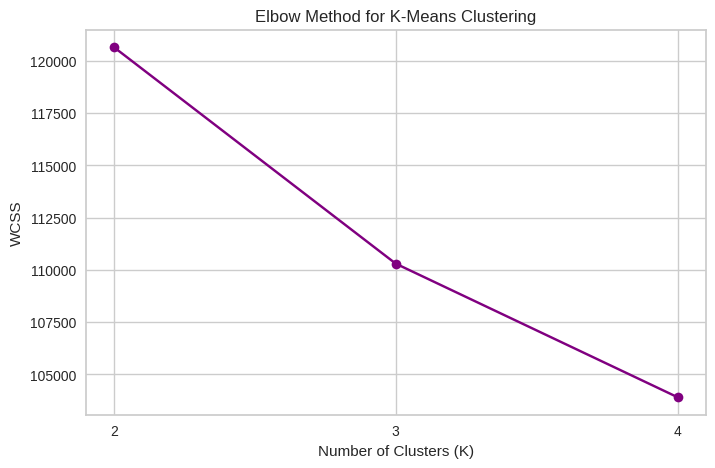

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    wcss_values,
    marker='o',
    linestyle='-',
    color='purple'
)

plt.title('Elbow Method for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(k_values)
plt.grid(True)
plt.show()

### Elbow Method Results

The WCSS decreased from 120660.71 for K=2 to 110300.84 for K=3, and then to 103908.01 for K=4. The largest decrease occurred between K=2 and K=3, while the improvement became smaller after K=3. Therefore, based on the Elbow Method, K=3 is selected as a reasonable number of clusters. This selection will be further evaluated using the Silhouette coefficient.

### **Silhouette Coefficient**


Silhouette Coefficient is used to assess the clustering quality, by examining how compact the clusters are and how well they are separated from each other. The average silhouette coefficient is calculated for K values from 2 to 10, and the optimal K is the one that maximizes this average.

The result will then be compared with the Elbow Method result (K=3).

K = 2, Average Silhouette = 0.1285
K = 3, Average Silhouette = 0.1093
K = 4, Average Silhouette = 0.0974
K = 5, Average Silhouette = 0.0845
K = 6, Average Silhouette = 0.0801
K = 7, Average Silhouette = 0.0777
K = 8, Average Silhouette = 0.0765
K = 9, Average Silhouette = 0.0748
K = 10, Average Silhouette = 0.0735


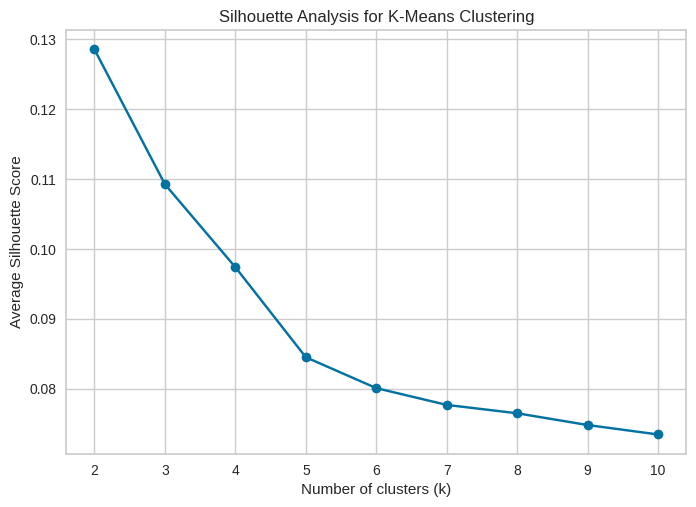

In [ ]:
from sklearn.metrics import silhouette_score

sil_k_values = range(2, 11)
silhouette_avg_values = []

for k in sil_k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_clustering_scaled)
    silhouette_avg = silhouette_score(X_clustering_scaled, kmeans.labels_)
    silhouette_avg_values.append(silhouette_avg)
    print(f"K = {k}, Average Silhouette = {silhouette_avg:.4f}")

plt.plot(sil_k_values , silhouette_avg_values, marker='o')
plt.title('Silhouette Analysis for K-Means Clustering')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.show()

Results show that the average silhouette coefficient was highest at K=2 (0.1285).
The average decreased as the number of clusters increased, reaching 0.0735 at K=10.


 However, all average silhouette coefficients were low and close to 0. Which means the clusters are not strongly separated.

 Therefore, based on the Silhouette coefficient, K=2 is the optimal number of clusters.

K=2, 3, and 4 were selected for detailed comparison because they achieved the three highest silhouette average values in the range tested.

### **Calinski-Harabasz Index**





The Calinski-Harabasz index was used as a third evaluation method. It compares how well the clusters are separated from each other with how compact each cluster is, where a higher value indicates better clustering. It was calculated for K values from 2 to 10.

K = 2, Calinski-Harabasz Index = 1602.48
K = 3, Calinski-Harabasz Index = 1345.88
K = 4, Calinski-Harabasz Index = 1157.36
K = 5, Calinski-Harabasz Index = 989.67
K = 6, Calinski-Harabasz Index = 882.43
K = 7, Calinski-Harabasz Index = 797.74
K = 8, Calinski-Harabasz Index = 736.35
K = 9, Calinski-Harabasz Index = 685.07
K = 10, Calinski-Harabasz Index = 640.87


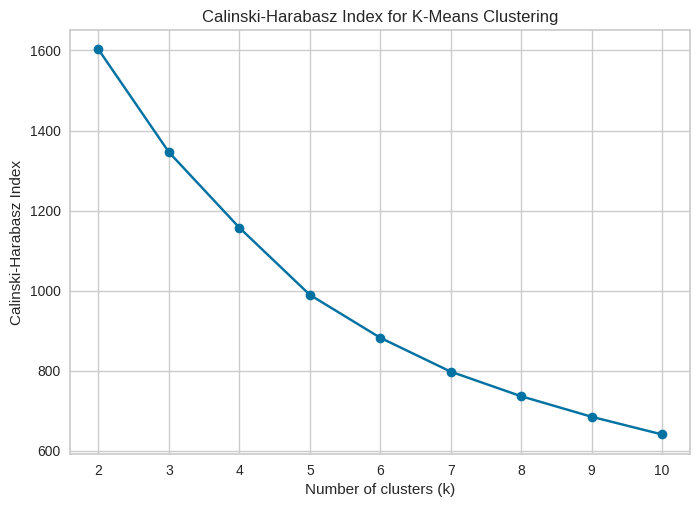

In [ ]:
from sklearn.metrics import calinski_harabasz_score

ch_k_values = range(2, 11)
ch_scores = []

for k in ch_k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_clustering_scaled)
    ch_score = calinski_harabasz_score(X_clustering_scaled, kmeans.labels_)
    ch_scores.append(ch_score)
    print(f"K = {k}, Calinski-Harabasz Index = {ch_score:.2f}")

plt.plot(ch_k_values, ch_scores, marker='o')
plt.title('Calinski-Harabasz Index for K-Means Clustering')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Calinski-Harabasz Index')
plt.show()

The Calinski-Harabasz index was highest at K=2 (1602.48) and decreased steadily as the number of clusters increased, reaching 640.87 at K=10. Therefore, based on the Calinski-Harabasz index, K=2 is the optimal number of clusters, which agrees with the Silhouette coefficient.

### Summary Table

In [ ]:
summary = pd.DataFrame({
    'K=2': [silhouette_avg_values[0], wcss_values[0], ch_scores[0]],
    'K=3': [silhouette_avg_values[1], wcss_values[1], ch_scores[1]],
    'K=4': [silhouette_avg_values[2], wcss_values[2], ch_scores[2]]
}, index=['Average Silhouette Width', 'Total Within-Cluster Sum of Square', 'Calinski-Harabasz Index'])
summary.round(4)

,K=2,K=3,K=4
Average Silhouette Width,0.1285,0.1093,0.0974
Total Within-Cluster Sum of Square,120660.7146,110300.8417,103908.0128
Calinski-Harabasz Index,1602.4756,1345.8791,1157.3607


The table summarizes the average silhouette width, the total within-cluster sum of square (WCSS), and the Calinski-Harabasz index for the three values of K.

### Interpretation for each K

**K = 2:**

achieved the highest average silhouette width (0.1285), meaning it has the best separation between clusters among the three values. It also has the highest WCSS (120660.71).

Only a small number of  objects had a negative silhouette value.

It also achieved the highest Calinski-Harabasz index (1602.48).

**K = 3:**

The average silhouette width decreased to 0.1093, while the WCSS decreased to 110300.84. This shows that the clusters became more compact than K=2 but less separated.

The percentage of objects with a negative silhouette value increased.

The Calinski-Harabasz index also decreased to 1345.88.

**K = 4:**

The lowest average silhouette width (0.0974) and the lowest WCSS (103908.01). The clusters are the most compact, but the separation between them is the weakest.

It had the largest number of objects with a negative silhouette value.

It also had the lowest Calinski-Harabasz index (1157.36).

### **The Best K Based on Majority Rule**

Three evaluation methods were used to select the optimal number of clusters:

**Elbow Method: K=3**

**Silhouette coefficient: K=2**

**Calinski-Harabasz index: K=2**

The Elbow Method only measured compactness while the Silhouette coefficient and the Calinski-Harabasz index considered both compactness and separation.

In addition, the WCSS decreased gradually and the bend at K=3 was not very sharp, so the Elbow result is less clear than the other two results.

Since two of the three methods selected K=2, it was chosen as the optimal number of clusters based on the majority rule.

**Final Choice: K = 2**

### **Visualization of Clusters**


For the scatter plot the two attributes  Daily_Steps and Resting_Heart_Rate were used to visualize the clusters because they had the largest difference between clusters among the numerical attributes.

In [ ]:
%pip install yellowbrick

### **K = 2**

The average silhouette score is: 0.12853654550527793


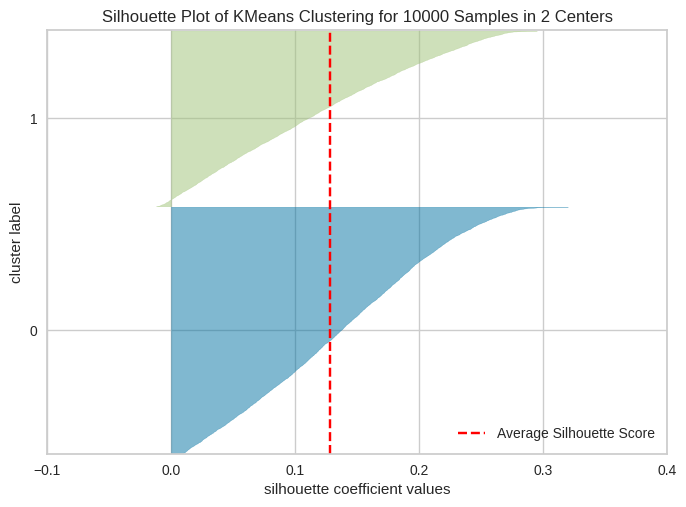

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 10000 Samples in 2 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
from yellowbrick.cluster import SilhouetteVisualizer

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
visualizer = SilhouetteVisualizer(kmeans, colors="yellowbrick")
visualizer.fit(X_clustering_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show()

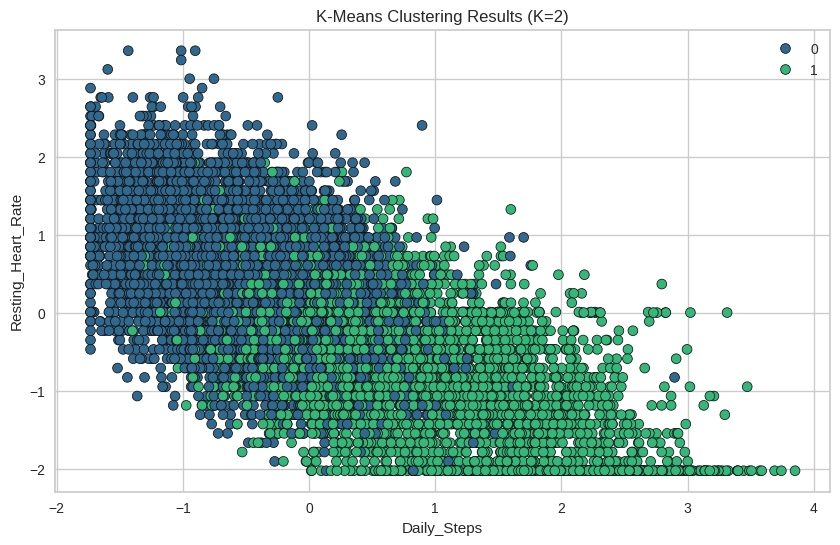

In [ ]:
import seaborn as sns

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_result = kmeans.fit(X_clustering_scaled)

clusters_df = pd.DataFrame(X_clustering_scaled, columns=X_clustering.columns)
clusters_df['Cluster'] = kmeans_result.labels_

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Daily_Steps', y='Resting_Heart_Rate', hue='Cluster', data=clusters_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=2)')
plt.xlabel('Daily_Steps')
plt.ylabel('Resting_Heart_Rate')
plt.legend()
plt.show()

The silhouette plot for K=2 shows that most objects have positive silhouette values, and only a small number of objects have negative values.

In the scatter plot, the two clusters differ mainly in Daily_Steps and Resting_Heart_Rate, although some overlap appears between them.

### **K = 3**

The average silhouette score is: 0.10925427864654294


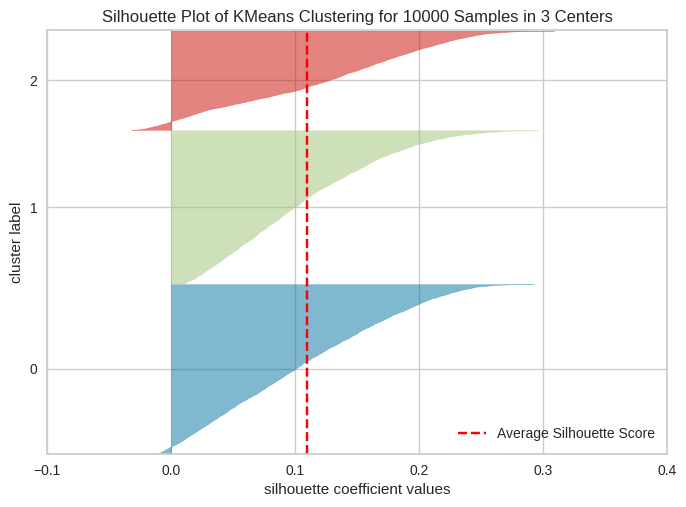

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 10000 Samples in 3 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
visualizer = SilhouetteVisualizer(kmeans, colors="yellowbrick")
visualizer.fit(X_clustering_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_result = kmeans.fit(X_clustering_scaled)

clusters_df = pd.DataFrame(X_clustering_scaled, columns=X_clustering.columns)
clusters_df['Cluster'] = kmeans_result.labels_

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Daily_Steps', y='Resting_Heart_Rate', hue='Cluster', data=clusters_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=3)')
plt.xlabel('Daily_Steps')
plt.ylabel('Resting_Heart_Rate')
plt.legend()
plt.show()

With K=3, more objects have negative silhouette values than with K=2, which shows more overlap between clusters.

The scatter plot shows a third group, but its boundaries are less clear.

### **K = 4**

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
visualizer = SilhouetteVisualizer(kmeans, colors="yellowbrick")
visualizer.fit(X_clustering_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show()

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_result = kmeans.fit(X_clustering_scaled)

clusters_df = pd.DataFrame(X_clustering_scaled, columns=X_clustering.columns)
clusters_df['Cluster'] = kmeans_result.labels_

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Daily_Steps', y='Resting_Heart_Rate', hue='Cluster', data=clusters_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=4)')
plt.xlabel('Daily_Steps')
plt.ylabel('Resting_Heart_Rate')
plt.legend()
plt.show()

*K*=4, the silhouette plot shows the largest number of negative values.

The scatter plot shows heavy overlap between the four clusters.

This confirms that a larger K does not mean the better separation of the clusters.

# **[7] Findings and Discussion**

The goal of this project was to predict daily stress levels using wearable and lifestyle data and to identify the factors linked to higher or lower stress. The dataset contained 10,000 records and 15 attributes: 14 attributes describing sleep, physical activity, diet, caffeine intake, screen time, and heart rate, and the class label Daily_Stress_Level [2].

In the preprocessing phase, missing values were handled using mean imputation, the User_ID attribute was removed, numerical attributes were normalized using Min-Max scaling, and categorical attributes were converted into numerical values.

After preprocessing, two data mining techniques were applied.

For classification, Decision Tree models were built using two attribute selection measures, Information Gain (Entropy) and Gini Index, with three train-test partitions (90/10, 80/20, and 70/30).
Because the High stress class had very few records (425 out of 10,000), the models had difficulty identifying it, so they were evaluated before and after merging High stress with Medium stress.

For clustering, K-Means was applied with K=2, 3, and 4, and the results were evaluated using the Elbow Method, the Silhouette coefficient, and the Calinski-Harabasz index.

Our key findings are summarized below.

## **Classification**

### **Information Gain (Entropy)**

As presented in Section 6, the Information Gain (Entropy) Decision Tree was evaluated using three partitions, before and after merging the High and Medium stress classes. The table below summarizes these results.

In [ ]:
# @title
entropy_results = pd.DataFrame({
    'Measure': ['Accuracy (3 classes)', 'Error Rate (3 classes)',
                'Accuracy (after merging)', 'Error Rate (after merging)'],
    '90% training, 10% testing': ['0.6680', '0.3320', '0.7310', '0.2690'],
    '80% training, 20% testing': ['0.6590', '0.3410', '0.7180', '0.2820'],
    '70% training, 30% testing': ['0.6523', '0.3477', '0.7093', '0.2907']})
entropy_results

Based on the results, the following observations can be made:


* **Accuracy:** Merging the classes gave the clearest improvement. The model was correct about 65–67% of the time with three stress levels, but this rose to 73.1% once High and Medium were combined, with the 90/10 partition performing best.

* **Error Rate:** Merging also reduced the model's mistakes. The model was wrong about 33–34.8% of the time with three stress levels, but this dropped to 26.9% once High and Medium were combined, with the 90/10 partition making the fewest errors.

* **Recall:** Merging made the biggest difference in detecting stress. The model identified only about 26.2–35.3% of High stress cases with three stress levels, but this rose to about 67.7–69.1% of Medium and High stress cases once they were combined, with the 80/20 partition detecting the most (69.1%).

* **Partitions:** The size of the partition had little effect. The accuracy of the three partitions differed by about 1.6 percentage point with three stress levels and about 2.2 points after merging.

In [ ]:
# @title
recall_comparison = pd.DataFrame({
    'High stress (3 classes)': [26.19, 35.29, 29.92],
    'Medium + High stress (after merging)': [68.88, 69.12, 67.70]
}, index=['90/10', '80/20', '70/30'])

recall_comparison.plot(kind='bar', figsize=(8, 5))
plt.title('Entropy Recall for Stressed Cases Before and After Merging')
plt.xlabel('Train/Test Split')
plt.ylabel('Recall (%)')
plt.ylim(0, 80)
plt.xticks(rotation=0)
plt.show()

The chart shows the large difference in recall before and after merging.

With three classes, the model detected only about a quarter to a third of High stress cases, while after merging it detected about 68–69% of Medium + High stress cases in every partition.

### **Gini Index**

Similarly, the Gini Index results from Section 6 are summarized in the table below.

In [ ]:
# @title
gini_results = pd.DataFrame({
    'Measure': ['Accuracy (3 classes)', 'Error Rate (3 classes)',
                'Accuracy (after merging)', 'Error Rate (after merging)'],
    '90% training, 10% testing': ['0.6580', '0.3420', '0.7190', '0.2810'],
    '80% training, 20% testing': ['0.6520', '0.3480', '0.6970', '0.3030'],
    '70% training, 30% testing': ['0.6560', '0.3440', '0.7007', '0.2993']})
gini_results

Based on the results, these observations can be made:

* **Accuracy:** The Gini model also benefited from merging. It was correct about 65–66% of the time with three stress levels, but this rose to 71.9% once High and Medium were combined, with the 90/10 partition performing best.

* **Error Rate:** Fewer mistakes followed the merge as well. The model was wrong about 34–35% of the time with three stress levels, but this dropped to 28.1% once High and Medium were combined, with the 90/10 partition making the fewest errors.

* **Effect of Merging:** Every partition improved after merging. The average accuracy was 65.5% with three stress levels, but this rose to 70.6% once High and Medium were combined, an improvement of about 5 percentage points.

* **Partitions:** Changing the train/test split made only a small difference. The three partitions were within 0.6 percentage points of each other with three stress levels, and within about 2 points after merging.

In [ ]:
# @title
merging_comparison = pd.DataFrame({
    'Gini (3 classes)': [65.8, 65.2, 65.6],
    'Gini (after merging)': [71.9, 69.7, 70.07],
    'Entropy (3 classes)': [66.8, 65.9, 65.23],
    'Entropy (after merging)': [73.1, 71.8, 70.93]
}, index=['90/10', '80/20', '70/30'])

merging_comparison.plot(kind='bar', figsize=(10, 6))
plt.title('Accuracy Before and After Merging the Classes')
plt.xlabel('Train/Test Split')
plt.ylabel('Accuracy (%)')
plt.ylim(60, 76)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

The chart shows that merging the classes improved the accuracy of both measures in every partition, by about 5 percentage points for Gini and 6 percentage points for Entropy on average.

### **The Best Model Between Information Gain and Gini Index**

The final comparison in Section 6 tested both measures on the same train/test split for each partition, and its results match the separate results above.

In [ ]:
# @title
comparison_table


Entropy achieved higher accuracy than Gini in all three partitions. However, the difference was small (between 0.9 and 2.1 percentage points), which means both measures performed similarly on this dataset. Merging the classes had a much larger effect on accuracy than the choice of attribute selection measure.

In [ ]:
# @title
comparison_table[['gini', 'entropy']].plot(kind='bar', figsize=(8, 5))
plt.title('Gini vs Entropy Accuracy (Same Train/Test Split)')
plt.xlabel('Train/Test Split')
plt.ylabel('Accuracy')
plt.ylim(0.65, 0.75)
plt.xticks(rotation=0)
plt.legend(['Gini', 'Entropy'])
plt.show()

### **Conclusion**

The best model is the Decision Tree using Information Gain (Entropy) with the 90/10 partition, with an accuracy of 73.1% and an error rate of 26.9%.


In [ ]:
# @title
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    final_tree,
    feature_names=final_tree.feature_names_in_,
    class_names=["Low", "Medium + High"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Final Decision Tree - Entropy (90/10)")
plt.show()

**Final Decision Tree Interpretation**

The final decision tree from Section 6 is shown again above.

It starts with Screen_Time_Hours, which gave the highest information gain, followed by Caffeine_Intake_mg, Physical_Activity_Level, and Diet_Type. Following its branches shows how the classification is achieved.

The first split already separates the records clearly. People with a normalized screen time of 0.471 or less (about 7.7 hours a day) were mostly Low stress (73%), while those above it were mostly Medium + High stress (64%).

* **Lowest stress:** screen time of about 7.7 hours or less, caffeine of about 290 mg or less, and Medium or High physical activity. 87% of these 2,726 training records were Low stress.
* **Highest stress:** screen time above about 7.7 hours, Low physical activity, and an Unhealthy or Average diet. 90% of these 805 training records were Medium + High stress.

These paths show that the model links less screen time, less caffeine, more physical activity, and a healthier diet with lower stress. Only the top levels are displayed because the full tree is too large to read.

## **Clustering**

The clustering results from Section 6 are summarized in the table below.

In [ ]:
summary.round(4)

As concluded in Section 6, **K=2** was selected as the optimal number of clusters based on the majority rule, since both the Silhouette coefficient (0.1285) and the Calinski-Harabasz index (1602.48) were highest at K=2. However, the low silhouette values show that the clusters overlap and do not form strongly separated groups.

The scatter plot below shows the **two clusters**, using Daily_Steps and Resting_Heart_Rate, the two numerical attributes with the largest difference between the clusters. The average values of all attributes and the stress level of each cluster are then compared to understand what each cluster represents.

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_result = kmeans.fit(X_clustering_scaled)

clusters_df = pd.DataFrame(X_clustering_scaled, columns=X_clustering.columns)
clusters_df['Cluster'] = kmeans_result.labels_

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Daily_Steps', y='Resting_Heart_Rate', hue='Cluster', data=clusters_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clusters (K=2)')
plt.xlabel('Daily_Steps')
plt.ylabel('Resting_Heart_Rate')
plt.legend(title='Cluster')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_result = kmeans.fit(X_clustering_scaled)

profile = df.copy()
profile['Cluster'] = kmeans_result.labels_

cluster_profile = profile.groupby('Cluster').mean().round(2).T
cluster_profile = cluster_profile.drop(index='Daily_Stress_Level')

stress = (pd.crosstab(profile['Cluster'], profile['Daily_Stress_Level'], normalize='index') * 100).round(1)
cluster_profile.loc['Low Stress (%)'] = stress[0]
cluster_profile.loc['Medium + High Stress (%)'] = stress[1]

cluster_profile.columns = ['Cluster 0', 'Cluster 1']
cluster_profile

In [ ]:
all_attributes = profile.columns.drop(['Daily_Stress_Level', 'Cluster'])

profile.groupby('Cluster')[all_attributes].mean().T.plot(kind='bar', figsize=(14, 6))
plt.title('Average Attribute Values in Each Cluster (K=2)')
plt.ylabel('Average Value (normalized 0–1; categories coded 0–2)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Cluster')
plt.show()

In [ ]:
sns.countplot(x='Cluster', hue='Daily_Stress_Level', data=profile)
plt.title('Stress Level in Each Cluster (K=2)')
plt.xlabel('Cluster')
plt.ylabel('Number of Records')
plt.legend(title='Stress Level', labels=['Low', 'Medium + High'])
plt.show()

As the scatter plot and the two charts show, the two clusters represent two different lifestyles:

* **Cluster 1 (4,159 records)** has the healthier lifestyle: more physical activity and daily steps, more sleep and deep sleep, a higher sleep quality score, a lower resting heart rate, and less caffeine and screen time. **77% of this cluster has Low stress.**
* **Cluster 0 (5,841 records)** shows the opposite pattern. **Only 44% of this cluster has Low stress**, while 56% has Medium + High stress.

Age, gender, and diet type were almost the same in both clusters, so the difference between them comes mainly from activity, sleep, and heart rate.

Although the stress label was not used in clustering, the two clusters still differ clearly in stress level. This shows that lifestyle habits are related to daily stress.

## **What We Learned and How It Can Help**

The results are meaningful in the context of our study, because both techniques connect healthier daily habits with lower stress.

**What each technique showed:**
* **Classification:** the decision tree's first splits used screen time, caffeine intake, physical activity, and diet to predict stress. People with less screen time, less caffeine, and more activity were mostly Low stress.
* **Clustering:** without using the stress label, K-Means separated a healthier group (more activity and sleep, lower heart rate) that had much lower stress (77% Low compared with 44%).
* **Class imbalance:** High stress was rare (425 of 10,000 records) and hard to identify, and merging it with Medium stress improved the results of both measures.

**Problem solution:**
The final model can be used to identify people who are likely to have Medium or High stress from their daily habits, with 73.1% accuracy. These people could then be encouraged to reduce screen time and caffeine and to be more physically active. However, the results show a relationship between lifestyle and stress, not that these habits cause stress.

## **Comparing the Two Techniques**

Classification and clustering were evaluated with different metrics. The best classification model reached 73.1% accuracy, so it predicted the stress level correctly for most people. The best clustering result had an average silhouette width of only 0.1285, which means the groups overlap and are not clearly separated.

Classification learns from the stress label, so it can predict the stress level of a new person, which clustering cannot do. Therefore, **classification is the more suitable technique for solving our problem**, with the Entropy Decision Tree (90/10) as the best model.

Clustering supported these results by finding, without the label, a healthier group with much lower stress. Both techniques pointed to physical activity as an important factor, and clustering also showed differences in sleep and heart rate between the two groups.

## **Comparison with the Research Paper**

We compared our findings with the research paper “Stress Detection Through Sleep-Based Physiological Signals: An Integrated Semi-Supervised and Supervised Learning Approach” [1], which also used a Decision Tree to detect stress.

The table below compares what each study measured.

In [ ]:
pd.set_option('display.max_colwidth', None)
comparison_with_paper = pd.DataFrame({
    'Research Paper [1]': ['One night in a sleep lab (polysomnography)',
                           'Heart rate during sleep, heart rate variability',
                           'Sleep efficiency, total sleep, sleep stages',
                           'Not included'],
    'Our Dataset': ['Daily wearable and lifestyle records',
                    'Resting heart rate',
                    'Sleep hours, deep sleep hours, sleep quality score',
                    'Screen time, caffeine, physical activity, diet, steps, water']
}, index=['Data collection', 'Heart rate', 'Sleep', 'Daily habits'])

comparison_with_paper

Both studies include heart rate and sleep, but they measured them differently. The paper's two most important attributes, heart rate during sleep and sleep efficiency, are not in our dataset. On the other hand, our dataset includes daily habits that the paper did not measure at all.

**Where our results agree:**
The paper found that higher heart rate and lower sleep efficiency were linked to higher stress. Our clustering showed the same direction: the cluster with more stress had a higher resting heart rate and fewer sleep hours. The paper also listed balancing the stress and non-stress classes as future work, while we merged High with Medium stress.

**Where our results differ:**
Our decision tree did not rely on heart rate or sleep in its first splits. It split mainly on screen time, caffeine intake, physical activity, and diet, which are exactly the attributes the paper did not have. This means that when daily habits are available, they separate stress levels better than the sleep and heart rate measures in our dataset.

The paper's Decision Tree reached 99% accuracy, while ours reached 73.1%. Four differences explain this:
1. **Labels:** the paper relabelled its data using a self-training model before training, while we used the dataset's original labels.
2. **Data size:** the paper's final dataset had about 500 records, while ours had 10,000.
3. **Measurements:** the paper used detailed sleep-lab signals, while our data comes from daily wearable summaries and habits.
4. **Tuning:** the paper tuned its models, while we used the default settings.

# **[8] References**

[1] J. Prayoonpruk, M. Kozlov, B. Ismalej, A. Neelam, X. Jiang, and N. Ho, “Stress detection through sleep-based physiological signals: An integrated semi-supervised and supervised learning approach,” in Proc. 2026 IEEE 16th Annu. Comput. Commun. Workshop Conf. (CCWC), 2026, pp. 27–33, doi: 10.1109/CCWC67433.2026.11393826.

[2] O. Kadam, “Wearable Tech: Sleep Quality & Stress,” Kaggle, 2026. [Online]. Available: https://www.kaggle.com/datasets/itzzomkar/wearable-tech-sleep-quality-and-stress. [Accessed: Nov. 4, 2026].